# Лабораторная работа №13: Fine-tuning diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Подготовить изображения/captions и fixed-seed baseline.
- Выполнить SD1.5 LoRA fine-tuning.
- Сравнить checkpoints, diversity и memorization.

## Теоретическая часть

Latent diffusion добавляет шум в latent space VAE, а U-Net предсказывает noise/velocity. LoRA адаптирует attention projections без изменения всех весов. Фиксированные seeds и prompts обязательны для сравнения checkpoints.

![Архитектура latent diffusion](https://raw.githubusercontent.com/CompVis/latent-diffusion/main/assets/modelfigure.png)


Latent diffusion обучает UNet предсказывать ε в пространстве VAE. LoRA добавляет обучаемые низкоранговые поправки к attention projections; VAE, text encoder и base UNet остаются замороженными. CLIP text similarity, разнообразие и ближайшая train генерация измеряют разные свойства и требуют ручного дополнения.

Для LoRA $W^{\prime}=W+BA$, где $B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r\ll\min(d,k)$. Noise-prediction минимизирует $\mathbb{E}_{x_0,\epsilon,t}\|\epsilon-\epsilon_\theta(z_t,t,c)\|_2^2$ на VAE-latents.

### Экспериментальный протокол

Основной эксперимент: SD 1.5 и 28 открытых реальных фотографий бабочек Wikimedia Commons при 512 px. `download_open_data.py` скачивает файлы и для каждого проверяет метаданные CC0-1.0 через Commons API, фиксирует страницу источника, URL лицензии и SHA256. Никакие файлы студента не требуются; `CV_LORA_DATA` задаёт альтернативный каталог с той же структурой metadata.jsonl. 3 независимых адаптера по 400 optimizer updates, checkpoint на 200/400; фиксированные held-out prompts и seeds. FAST_DEV_RUN: 256 px, один update, только smoke. Требуются GPU, Pillow, pip install diffusers transformers accelerate peft safetensors torchvision; на CPU не подменять обучение имитацией. CV_ARTIFACTS указывает на постоянный каталог Drive.

### Материалы

- [Diffusers LoRA training](https://huggingface.co/docs/diffusers/training/lora)
- [Latent Diffusion](https://arxiv.org/abs/2112.10752)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch

SEED = 42
FAST_DEV_RUN = False  # True: только проверка связности, не для сдачи

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# У каждой лабы своя папка; DATA_ROOT совпадает с каталогом download_open_data.py
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab13'))
DATA_ROOT = Path(os.getenv('CV_LORA_DATA', 'data/lab13'))
for folder in (ARTIFACTS, DATA_ROOT):
    folder.mkdir(parents=True, exist_ok=True)

# Бюджет по протоколу: полный режим — 512 px, 400 updates, checkpoints на 200/400
RESOLUTION = 256 if FAST_DEV_RUN else 512
MAX_STEPS = 1 if FAST_DEV_RUN else 400
CHECKPOINT_STEPS = [1] if FAST_DEV_RUN else [200, 400]
NOTEBOOK_T0 = time.time()  # начало прогона — для итогового run_info.json

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(value, ensure_ascii=False, indent=2, default=str)
    destination.write_text(text, encoding='utf-8')

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN,
       'artifacts': str(ARTIFACTS), 'data': str(DATA_ROOT),
       'resolution': RESOLUTION, 'max_steps': MAX_STEPS, 'checkpoints': CHECKPOINT_STEPS})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab13', 'data': 'data\\lab13', 'resolution': 512, 'max_steps': 400, 'checkpoints': [200, 400]}


### Задание 1. Лицензия и валидация изображений

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей.

**Результат.** Проверяемое состояние «Лицензия и валидация изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей» и его результат доступен следующему этапу.

In [2]:
# Задание 1. Лицензия и валидация изображений
import hashlib
from collections import Counter
from PIL import Image, ImageOps
from download_open_data import download  # скрипт лежит в корне проекта

EXPECTED_LICENSE, CC0_URL = 'CC0-1.0', 'creativecommons.org/publicdomain/zero/1.0/'
CAPTION_PREFIX = 'a photo of sks butterfly'
MIN_SIDE = 256

def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding='utf-8').splitlines() if line.strip()]

def write_jsonl(path, rows):
    Path(path).write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in rows), encoding='utf-8')

def average_hash(image, size=8):
    """64-битный aHash: ловит почти-дубликаты, которые различаются только пересжатием/размером."""
    pixels = np.asarray(image.convert('L').resize((size, size), Image.BILINEAR), dtype=np.float32)
    return (pixels > pixels.mean()).flatten()

metadata_path = DATA_ROOT / 'metadata.jsonl'
if not metadata_path.exists():
    # Скрипт сам проверяет LicenseShortName=CC0 по Commons API для каждого файла
    download(DATA_ROOT)
records = read_jsonl(metadata_path)

rows, problems, hashes = [], [], {}
for r in records:
    path = DATA_ROOT / r['file_name']
    issues = []
    if not path.is_file():
        problems.append(f"{r['file_name']}: файл отсутствует")
        continue
    raw = path.read_bytes()
    sha256 = hashlib.sha256(raw).hexdigest()
    if sha256 != r['sha256']:
        issues.append('sha256 не совпадает с metadata.jsonl')
    try:
        with Image.open(path) as image:
            source_mode, source_format = image.mode, image.format
            rgb = ImageOps.exif_transpose(image).convert('RGB')
            rgb.load()  # полное декодирование, а не только заголовок
    except Exception as error:
        problems.append(f"{r['file_name']}: не декодируется ({error})")
        continue
    pixels = np.asarray(rgb)
    if pixels.ndim != 3 or pixels.shape[2] != 3:
        issues.append(f'после convert(RGB) форма {pixels.shape}')
    if min(rgb.size) < MIN_SIDE:
        issues.append(f'меньшая сторона {min(rgb.size)} < {MIN_SIDE}')
    if pixels.std() < 1.0:
        issues.append('почти константное изображение')
    if r.get('license') != EXPECTED_LICENSE or CC0_URL not in r.get('license_url', ''):
        issues.append(f"лицензия {r.get('license')} {r.get('license_url')}")
    if not r.get('source_url', '').startswith('https://commons.wikimedia.org/'):
        issues.append('нет страницы источника Commons')
    caption = r.get('text', '').strip()
    if not caption.startswith(CAPTION_PREFIX):
        issues.append(f'подпись без токена «{CAPTION_PREFIX}»')
    hashes[r['file_name']] = average_hash(rgb)
    problems += [f"{r['file_name']}: {issue}" for issue in issues]
    rows.append({'file_name': r['file_name'], 'sha256': sha256, 'format': source_format, 'source_mode': source_mode,
                 'width': rgb.width, 'height': rgb.height, 'mean_rgb': [round(float(v), 1) for v in pixels.mean((0, 1))],
                 'license': r.get('license'), 'license_url': r.get('license_url'), 'source_url': r.get('source_url'),
                 'author_as_reported': r.get('author_as_reported', ''), 'caption': caption, 'issues': issues})

# Уникальность: точные дубликаты по sha256, подписи, почти-дубликаты по aHash
for field, label in (('sha256', 'одинаковые файлы'), ('caption', 'одинаковые подписи')):
    repeated = [value for value, n in Counter(row[field] for row in rows).items() if n > 1]
    problems += [f'{label}: {value[:60]}' for value in repeated]
names = sorted(hashes)
hamming = {(a, b): int((hashes[a] != hashes[b]).sum()) for i, a in enumerate(names) for b in names[i + 1:]}
NEAR_DUP_BITS = 5
near_duplicates = [{'a': a, 'b': b, 'hamming': d} for (a, b), d in hamming.items() if d <= NEAR_DUP_BITS]
problems += [f"почти-дубликат {p['a']} ~ {p['b']} (hamming={p['hamming']})" for p in near_duplicates]

write_jsonl(ARTIFACTS / 'image_validation.jsonl', rows)
validation = {
    'data_root': str(DATA_ROOT), 'n_metadata': len(records), 'n_valid': sum(not row['issues'] for row in rows),
    'licenses': dict(Counter(row['license'] for row in rows)),
    'source_modes': dict(Counter(row['source_mode'] for row in rows)),
    'width_range': [min(row['width'] for row in rows), max(row['width'] for row in rows)],
    'height_range': [min(row['height'] for row in rows), max(row['height'] for row in rows)],
    'unique_sha256': len({row['sha256'] for row in rows}), 'unique_captions': len({row['caption'] for row in rows}),
    'min_ahash_hamming': min(hamming.values()), 'near_dup_threshold_bits': NEAR_DUP_BITS,
    'near_duplicates': near_duplicates, 'problems': problems,
    'license_note': 'CC0 подтверждён по опубликованным метаданным Commons, а не юридической экспертизой',
}
save_json('data_validation.json', validation)
print(json.dumps({k: v for k, v in validation.items() if k != 'near_duplicates'}, ensure_ascii=False, indent=2))
assert not problems, f'Проверка данных не пройдена: {problems}'
TRAIN_RECORDS = [r for r in records if r['file_name'] in {row['file_name'] for row in rows}]
print(f'OK: {len(TRAIN_RECORDS)} изображений прошли проверку → {ARTIFACTS / "image_validation.jsonl"}')

{
  "data_root": "data\\lab13",
  "n_metadata": 28,
  "n_valid": 28,
  "licenses": {
    "CC0-1.0": 28
  },
  "source_modes": {
    "RGB": 28
  },
  "width_range": [
    960,
    960
  ],
  "height_range": [
    540,
    1281
  ],
  "unique_sha256": 28,
  "unique_captions": 28,
  "min_ahash_hamming": 8,
  "near_dup_threshold_bits": 5,
  "problems": [],
  "license_note": "CC0 подтверждён по опубликованным метаданным Commons, а не юридической экспертизой"
}
OK: 28 изображений прошли проверку → artifacts\lab13\image_validation.jsonl


### Задание 2. Отложенные текстовые запросы

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями.

**Результат.** Проверяемое состояние «Отложенные текстовые запросы» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями» и его результат доступен следующему этапу.

In [3]:
# Задание 2. Отложенные текстовые запросы и seeds
import re

# Prompts придуманы до обучения и описывают сцены, которых нет в train captions:
# новые фоны/стили проверяют, перенёс ли адаптер «sks butterfly», а не запомнил ли фото.
EVAL_PROMPTS = [
    'a photo of sks butterfly resting on a snowy pine branch',
    'a photo of sks butterfly on a wooden fence at sunset',
    'a photo of sks butterfly sitting on a desert cactus',
    'a photo of sks butterfly on a street lamp in a city at night',
    'a photo of sks butterfly on a raindrop covered window',
    'a photo of sks butterfly on an old book on a table',
    'a watercolor painting of sks butterfly',
    'a pencil sketch of sks butterfly',
]
EVAL_SEEDS = [1000, 1001, 1002, 1003]
if FAST_DEV_RUN:  # smoke: подмножество тех же запросов, а не другие запросы
    EVAL_PROMPTS, EVAL_SEEDS = EVAL_PROMPTS[:2], EVAL_SEEDS[:1]

# Одинаковый inference-протокол для baseline и всех checkpoints
INFERENCE = {'num_inference_steps': 10 if FAST_DEV_RUN else 30, 'guidance_scale': 7.5,
             'height': RESOLUTION, 'width': RESOLUTION, 'scheduler': 'pipeline default'}

def normalize(text):
    return ' '.join(re.sub(r'[^a-z0-9 ]+', ' ', text.lower()).split())

STOPWORDS = {'a', 'an', 'the', 'of', 'on', 'in', 'at', 'with', 'and', 'photo', 'sks', 'butterfly'}
def content_words(text):
    return set(normalize(text).split()) - STOPWORDS

train_captions = [r['text'] for r in TRAIN_RECORDS]
train_norm = {normalize(c) for c in train_captions}
OVERLAP_LIMIT = 0.5  # доля общих содержательных слов (Jaccard), выше которой prompt считаем утечкой

prompt_rows, leaks = [], []
for i, prompt in enumerate(EVAL_PROMPTS):
    words = content_words(prompt)
    overlaps = [(len(words & content_words(c)) / max(1, len(words | content_words(c))), c) for c in train_captions]
    best_overlap, best_caption = max(overlaps)
    exact = normalize(prompt) in train_norm
    substring = any(normalize(prompt) in t or t in normalize(prompt) for t in train_norm)
    row = {'prompt_id': f'p{i:02d}', 'prompt': prompt, 'exact_train_match': exact, 'substring_of_train': substring,
           'max_content_jaccard': round(best_overlap, 3), 'closest_train_caption': best_caption,
           'shared_words': sorted(words & content_words(best_caption))}
    prompt_rows.append(row)
    if exact or substring or best_overlap > OVERLAP_LIMIT:
        leaks.append(row)

assert len(set(map(normalize, EVAL_PROMPTS))) == len(EVAL_PROMPTS), 'Повторяющиеся prompts'
assert len(set(EVAL_SEEDS)) == len(EVAL_SEEDS), 'Повторяющиеся seeds'
assert not set(EVAL_SEEDS) & {SEED}, 'Eval seeds не должны совпадать с seed обучения'

spec = {'prompts': EVAL_PROMPTS, 'seeds': EVAL_SEEDS, 'inference': INFERENCE}
EVAL_SPEC_SHA256 = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
save_json('eval_prompts.json', {**spec, 'spec_sha256': EVAL_SPEC_SHA256, 'fast_dev_run': FAST_DEV_RUN,
                                'n_generations_per_model': len(EVAL_PROMPTS) * len(EVAL_SEEDS),
                                'overlap_limit': OVERLAP_LIMIT, 'checks': prompt_rows})

for row in prompt_rows:
    print(f"{row['prompt_id']} jaccard={row['max_content_jaccard']:.2f} exact={row['exact_train_match']} "
          f"shared={row['shared_words']} | {row['prompt']}")
print(f'{len(EVAL_PROMPTS)} prompts × {len(EVAL_SEEDS)} seeds = {len(EVAL_PROMPTS) * len(EVAL_SEEDS)} генераций на модель; '
      f'spec_sha256={EVAL_SPEC_SHA256[:12]}…')
assert not leaks, f'Prompts пересекаются с обучающими подписями: {[r["prompt"] for r in leaks]}'
print('OK: точных совпадений и подстрок train captions нет →', ARTIFACTS / 'eval_prompts.json')

p00 jaccard=0.00 exact=False shared=[] | a photo of sks butterfly resting on a snowy pine branch
p01 jaccard=0.00 exact=False shared=[] | a photo of sks butterfly on a wooden fence at sunset
p02 jaccard=0.00 exact=False shared=[] | a photo of sks butterfly sitting on a desert cactus
p03 jaccard=0.00 exact=False shared=[] | a photo of sks butterfly on a street lamp in a city at night
p04 jaccard=0.00 exact=False shared=[] | a photo of sks butterfly on a raindrop covered window
p05 jaccard=0.00 exact=False shared=[] | a photo of sks butterfly on an old book on a table
p06 jaccard=0.00 exact=False shared=[] | a watercolor painting of sks butterfly
p07 jaccard=0.00 exact=False shared=[] | a pencil sketch of sks butterfly
8 prompts × 4 seeds = 32 генераций на модель; spec_sha256=de044a645f01…
OK: точных совпадений и подстрок train captions нет → artifacts\lab13\eval_prompts.json


### Задание 3. Baseline SD на фиксированных запросах

*Вес: 1 балл.*

**Постановка.** Baseline до обучения и сопоставимый inference protocol позволяют увидеть фактический вклад LoRA. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds.

**Результат.** Проверяемое состояние «Baseline SD на фиксированных запросах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds» и его результат доступен следующему этапу.

W1024 13:19:06.342000 34220 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

{
  "model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "dtype": "torch.float16",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3060",
  "scheduler": "PNDMScheduler",
  "safety_checker": null,
  "lora_params_in_unet": 0,
  "eval_spec_sha256": "de044a645f01a2ee49ba85e71a1322fed2fadebaf0217b37e9bd88931d85976a",
  "inference": {
    "num_inference_steps": 30,
    "guidance_scale": 7.5,
    "height": 512,
    "width": 512,
    "scheduler": "pipeline default"
  },
  "n_images": 32,
  "n_generated_now": 0,
  "sec_per_image": null,
  "wall_seconds": 0.1,
  "gpu_peak_memory_gib": 2.61,
  "repeat_mean_abs_pixel_diff": 0.0,
  "versions": {
    "torch": "2.11.0+cu128",
    "diffusers": "0.41.0",
    "transformers": "5.17.0"
  }
}


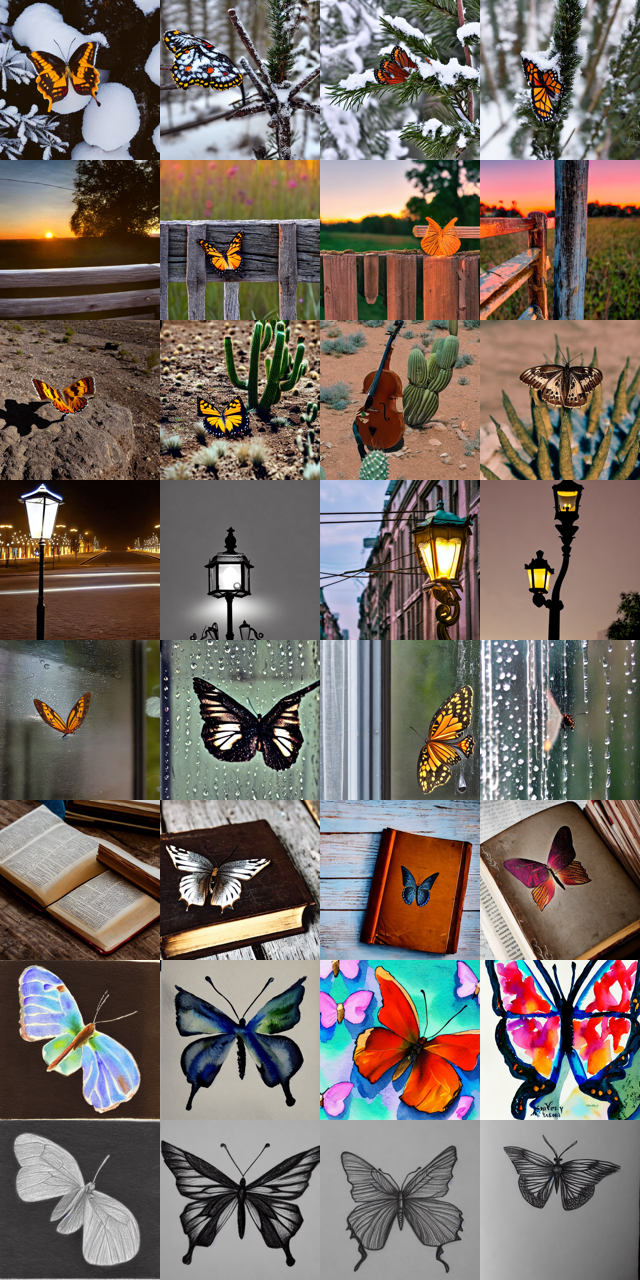

In [4]:
# Задание 3. Baseline SD 1.5 на фиксированных запросах (до установки LoRA)
import importlib.metadata as metadata
from diffusers import StableDiffusionPipeline

MODEL_ID = os.getenv('CV_SD_MODEL', 'stable-diffusion-v1-5/stable-diffusion-v1-5')
if not FAST_DEV_RUN:
    assert DEVICE == 'cuda', 'Baseline и обучение требуют GPU; на CPU результат не подменяется имитацией'
DTYPE = torch.float16 if DEVICE == 'cuda' else torch.float32
GEN_DIR = ARTIFACTS / 'generations'

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE,
    safety_checker=None, requires_safety_checker=False,  # иначе часть картинок заменяется чёрными
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)

def lora_param_count(unet):
    return sum(p.numel() for name, p in unet.named_parameters() if 'lora' in name.lower())

# Baseline обязан быть «чистой» моделью: в U-Net ещё нет ни одного LoRA-слоя
assert lora_param_count(pipe.unet) == 0 and getattr(pipe.unet, 'peft_config', None) is None, 'В U-Net уже есть LoRA'

def generate_set(pipeline, tag, overwrite=False):
    """Генерирует EVAL_PROMPTS × EVAL_SEEDS с протоколом INFERENCE; один и тот же код для baseline и checkpoints."""
    out_dir = GEN_DIR / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    rows, seconds = [], []
    for prompt_id, prompt in enumerate(EVAL_PROMPTS):
        for seed in EVAL_SEEDS:
            path = out_dir / f'p{prompt_id:02d}_s{seed}.png'
            if overwrite or not path.exists():
                generator = torch.Generator(device=DEVICE).manual_seed(seed)
                t0 = time.time()
                with torch.inference_mode():
                    image = pipeline(prompt, generator=generator,
                                     num_inference_steps=INFERENCE['num_inference_steps'],
                                     guidance_scale=INFERENCE['guidance_scale'],
                                     height=INFERENCE['height'], width=INFERENCE['width']).images[0]
                seconds.append(time.time() - t0)
                image.save(path)
            rows.append({'model': tag, 'prompt_id': f'p{prompt_id:02d}', 'prompt': prompt, 'seed': seed,
                         'file': path.relative_to(ARTIFACTS).as_posix(),
                         'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
    write_jsonl(out_dir / 'manifest.jsonl', rows)
    return rows, seconds

def contact_sheet(rows, path, thumb=160):
    """Сетка: строки — prompts, столбцы — seeds."""
    sheet = Image.new('RGB', (thumb * len(EVAL_SEEDS), thumb * len(EVAL_PROMPTS)), 'white')
    for k, row in enumerate(rows):
        with Image.open(ARTIFACTS / row['file']) as image:
            sheet.paste(image.convert('RGB').resize((thumb, thumb)),
                        ((k % len(EVAL_SEEDS)) * thumb, (k // len(EVAL_SEEDS)) * thumb))
    sheet.save(path)
    return sheet

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
t_start = time.time()
baseline_rows, baseline_seconds = generate_set(pipe, 'baseline')
baseline_wall = time.time() - t_start

# Воспроизводимость: повторная генерация первой пары prompt/seed тем же протоколом
generator = torch.Generator(device=DEVICE).manual_seed(EVAL_SEEDS[0])
with torch.inference_mode():
    repeat = pipe(EVAL_PROMPTS[0], generator=generator, num_inference_steps=INFERENCE['num_inference_steps'],
                  guidance_scale=INFERENCE['guidance_scale'],
                  height=INFERENCE['height'], width=INFERENCE['width']).images[0]
with Image.open(ARTIFACTS / baseline_rows[0]['file']) as first:
    repeat_diff = float(np.abs(np.asarray(first.convert('RGB'), np.float32) - np.asarray(repeat, np.float32)).mean())

sheet = contact_sheet(baseline_rows, ARTIFACTS / 'baseline_grid.png')
baseline_info = {
    'model_id': MODEL_ID, 'dtype': str(DTYPE), 'device': DEVICE,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'scheduler': type(pipe.scheduler).__name__, 'safety_checker': None,
    'lora_params_in_unet': lora_param_count(pipe.unet),
    'eval_spec_sha256': EVAL_SPEC_SHA256, 'inference': INFERENCE,
    'n_images': len(baseline_rows), 'n_generated_now': len(baseline_seconds),
    'sec_per_image': round(float(np.mean(baseline_seconds)), 2) if baseline_seconds else None,
    'wall_seconds': round(baseline_wall, 1),
    'gpu_peak_memory_gib': round(torch.cuda.max_memory_allocated() / 2**30, 2) if torch.cuda.is_available() else None,
    'repeat_mean_abs_pixel_diff': round(repeat_diff, 3),
    'versions': {p: metadata.version(p) for p in ['torch', 'diffusers', 'transformers']},
}
save_json('baseline_info.json', baseline_info)
print(json.dumps(baseline_info, ensure_ascii=False, indent=2))
assert len(baseline_rows) == len(EVAL_PROMPTS) * len(EVAL_SEEDS)
assert repeat_diff < 2.0, f'Генерация с тем же seed не воспроизводится: mean |Δ| = {repeat_diff:.2f}'
display(sheet)  # строки — prompts p00…, столбцы — seeds

### Задание 4. Подготовка пар изображение–caption

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон.

**Результат.** Проверяемое состояние «Подготовка пар изображение–caption» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон» и его результат доступен следующему этапу.

In [5]:
# Задание 4. Пары изображение–caption: препроцессинг, токенизация, проверка длины и диапазона
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

tokenizer = pipe.tokenizer
MAX_TOKENS = tokenizer.model_max_length  # 77 у CLIP SD 1.5, включая BOS/EOS
TRAIN_BATCH_SIZE = 1 if FAST_DEV_RUN else 2

class CaptionedImages(Dataset):
    """Изображение → [-1, 1], 3×R×R; caption → input_ids длины MAX_TOKENS."""
    def __init__(self, records, root, resolution, flip=True):
        self.records, self.root = records, Path(root)
        self.transform = transforms.Compose([
            transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BICUBIC),  # меньшая сторона → R
            transforms.CenterCrop(resolution),
            transforms.RandomHorizontalFlip(0.5 if flip else 0.0),
            transforms.ToTensor(),                 # [0, 1]
            transforms.Normalize([0.5] * 3, [0.5] * 3),  # [-1, 1], как ожидает VAE
        ])
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        r = self.records[i]
        with Image.open(self.root / r['file_name']) as image:
            pixels = self.transform(ImageOps.exif_transpose(image).convert('RGB'))
        ids = tokenizer(r['text'], padding='max_length', truncation=True, max_length=MAX_TOKENS,
                        return_tensors='pt').input_ids[0]
        return {'pixel_values': pixels, 'input_ids': ids, 'index': i}

train_dataset = CaptionedImages(TRAIN_RECORDS, DATA_ROOT, RESOLUTION)
loader_generator = torch.Generator().manual_seed(SEED)  # одинаковый порядок батчей для всех конфигураций
train_loader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
                          generator=loader_generator, drop_last=False, num_workers=0)

# Длина: сколько токенов у caption без обрезки (обрезанный хвост модель не увидит)
def token_length(text):
    return len(tokenizer(text, truncation=False).input_ids)

validated = {row['file_name']: row for row in rows}  # результаты задания 1
pair_rows = []
for r in TRAIN_RECORDS:
    row = validated[r['file_name']]
    n_tokens = token_length(r['text'])
    pair_rows.append({'file_name': r['file_name'], 'caption': r['text'], 'n_tokens': n_tokens,
                      'truncated': n_tokens > MAX_TOKENS, 'source_size': [row['width'], row['height']],
                      'upscaled': min(row['width'], row['height']) < RESOLUTION})
eval_token_lengths = {prompt: token_length(prompt) for prompt in EVAL_PROMPTS}

# Диапазон и форма: полный проход по датасету без аугментации + один батч из loader
check_dataset = CaptionedImages(TRAIN_RECORDS, DATA_ROOT, RESOLUTION, flip=False)
all_pixels = torch.stack([check_dataset[i]['pixel_values'] for i in range(len(check_dataset))])
batch = next(iter(train_loader))
decoded = tokenizer.decode(batch['input_ids'][0], skip_special_tokens=True)

# Латенты VAE для одного батча: так увидит изображения U-Net при обучении
with torch.inference_mode():
    latents = pipe.vae.encode(batch['pixel_values'].to(DEVICE, DTYPE)).latent_dist.sample()
    latents = latents * pipe.vae.config.scaling_factor

dataset_summary = {
    'n_pairs': len(train_dataset), 'resolution': RESOLUTION, 'batch_size': TRAIN_BATCH_SIZE,
    'batches_per_epoch': len(train_loader),
    'preprocess': 'Resize(shorter=R, bicubic) → CenterCrop(R) → RandomHFlip(0.5) → [-1, 1]',
    'pixel_shape': list(all_pixels.shape[1:]),
    'pixel_min': round(all_pixels.min().item(), 4), 'pixel_max': round(all_pixels.max().item(), 4),
    'pixel_mean': round(all_pixels.mean().item(), 4), 'pixel_std': round(all_pixels.std().item(), 4),
    'n_upscaled': sum(r['upscaled'] for r in pair_rows),
    'max_tokens': MAX_TOKENS,
    'caption_tokens': {'min': min(r['n_tokens'] for r in pair_rows), 'max': max(r['n_tokens'] for r in pair_rows),
                       'mean': round(float(np.mean([r['n_tokens'] for r in pair_rows])), 1)},
    'n_truncated': sum(r['truncated'] for r in pair_rows),
    'eval_prompt_tokens_max': max(eval_token_lengths.values()),
    'batch_input_ids_shape': list(batch['input_ids'].shape),
    'decoded_first_caption': decoded,
    'latent_shape': list(latents.shape[1:]),
    'latent_std_scaled': round(latents.float().std().item(), 3),  # ≈1 после scaling_factor
}
write_jsonl(ARTIFACTS / 'train_pairs.jsonl', pair_rows)
save_json('dataset_summary.json', dataset_summary)
print(json.dumps(dataset_summary, ensure_ascii=False, indent=2))

assert all_pixels.min() >= -1.0 and all_pixels.max() <= 1.0, 'Пиксели вне [-1, 1]'
assert tuple(all_pixels.shape[1:]) == (3, RESOLUTION, RESOLUTION)
assert batch['input_ids'].shape[1] == MAX_TOKENS
assert dataset_summary['n_truncated'] == 0, 'Есть captions длиннее 77 токенов — хвост обрежется'
assert dataset_summary['eval_prompt_tokens_max'] <= MAX_TOKENS
assert latents.shape[-1] == RESOLUTION // 8, 'VAE должен уменьшать сторону в 8 раз'
print(f'OK: {len(train_dataset)} пар, {len(train_loader)} батчей/эпоху → {ARTIFACTS / "train_pairs.jsonl"}')

{
  "n_pairs": 28,
  "resolution": 512,
  "batch_size": 2,
  "batches_per_epoch": 14,
  "preprocess": "Resize(shorter=R, bicubic) → CenterCrop(R) → RandomHFlip(0.5) → [-1, 1]",
  "pixel_shape": [
    3,
    512,
    512
  ],
  "pixel_min": -1.0,
  "pixel_max": 1.0,
  "pixel_mean": -0.1419,
  "pixel_std": 0.5172,
  "n_upscaled": 0,
  "max_tokens": 77,
  "caption_tokens": {
    "min": 10,
    "max": 23,
    "mean": 15.0
  },
  "n_truncated": 0,
  "eval_prompt_tokens_max": 16,
  "batch_input_ids_shape": [
    2,
    77
  ],
  "decoded_first_caption": "a photo of sks butterfly , black and white butterfly near shirahama",
  "latent_shape": [
    4,
    64,
    64
  ],
  "latent_std_scaled": 0.774
}
OK: 28 пар, 14 батчей/эпоху → artifacts\lab13\train_pairs.jsonl


### Задание 5. Заморозка основы и конфигурации LoRA

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR.

**Результат.** Проверяемое состояние «Заморозка основы и конфигурации LoRA» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR» и его результат доступен следующему этапу.

In [6]:
# Задание 5. Заморозка основы, тренировочный schedule и три конфигурации rank/LR
from diffusers import DDPMScheduler
from diffusers.optimization import get_scheduler
from peft import LoraConfig

# 1) Заморозка: VAE, text encoder и U-Net не обучаются; обучаться будут только LoRA-матрицы
for module in (pipe.vae, pipe.text_encoder, pipe.unet):
    module.requires_grad_(False)
pipe.vae.eval(); pipe.text_encoder.eval()

def count_params(module):
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable

frozen_report = {name: dict(zip(('total', 'trainable'), count_params(getattr(pipe, name))))
                 for name in ('vae', 'text_encoder', 'unet')}
assert all(v['trainable'] == 0 for v in frozen_report.values()), 'Основа не заморожена'

@torch.no_grad()
def unet_base_checksum(unet):
    """Сумма |w| по весам основы U-Net (без LoRA): в задании 6 проверим, что основа не изменилась."""
    return float(sum(p.detach().double().abs().sum().item()
                     for name, p in unet.named_parameters() if 'lora' not in name.lower()))
BASE_UNET_CHECKSUM = unet_base_checksum(pipe.unet)

# 2) Тренировочный schedule: шум DDPM SD 1.5 (ε-prediction) + cosine LR с warmup
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder='scheduler')
TRAIN_SCHEDULE = {
    'noise_scheduler': type(noise_scheduler).__name__,
    'num_train_timesteps': noise_scheduler.config.num_train_timesteps,
    'prediction_type': noise_scheduler.config.prediction_type,
    'beta_schedule': noise_scheduler.config.beta_schedule,
    'timestep_sampling': 'uniform[0, T)',
    'max_steps': MAX_STEPS, 'checkpoint_steps': CHECKPOINT_STEPS,
    'batch_size': TRAIN_BATCH_SIZE, 'resolution': RESOLUTION,
    'lr_scheduler': 'cosine', 'warmup_steps': 0 if FAST_DEV_RUN else 20,
    'optimizer': 'AdamW(betas=(0.9, 0.999), weight_decay=1e-2)', 'max_grad_norm': 1.0,
    'mixed_precision': 'fp16 autocast, LoRA-параметры в fp32, GradScaler',
    'gradient_checkpointing': True, 'train_seed': SEED,
}

# 3) Три конфигурации: A→B меняет только rank, B→C меняет только LR.
# alpha = rank, т. е. масштаб alpha/r = 1: rank не меняет силу поправки сам по себе.
LORA_TARGETS = ['to_q', 'to_k', 'to_v', 'to_out.0']  # проекции self- и cross-attention U-Net
LORA_CONFIGS = [
    {'name': 'r4_lr1e-4',  'rank': 4,  'alpha': 4,  'lr': 1e-4},
    {'name': 'r16_lr1e-4', 'rank': 16, 'alpha': 16, 'lr': 1e-4},
    {'name': 'r16_lr3e-4', 'rank': 16, 'alpha': 16, 'lr': 3e-4},
]

def make_lora_config(cfg):
    return LoraConfig(r=cfg['rank'], lora_alpha=cfg['alpha'], init_lora_weights='gaussian',  # B=0 → старт = baseline
                      target_modules=LORA_TARGETS, lora_dropout=0.0)

# Фактическое число обучаемых параметров: временно ставим адаптер, считаем, снимаем
for cfg in LORA_CONFIGS:
    pipe.unet.add_adapter(make_lora_config(cfg), adapter_name=cfg['name'])
    lora_params = [p for name, p in pipe.unet.named_parameters() if f'.{cfg["name"]}.' in name]
    cfg['trainable_params'] = sum(p.numel() for p in lora_params)
    cfg['n_lora_tensors'] = len(lora_params)
    cfg['share_of_unet'] = round(cfg['trainable_params'] / frozen_report['unet']['total'], 5)
    cfg['lora_file_mb_fp32'] = round(cfg['trainable_params'] * 4 / 2**20, 2)
    pipe.unet.delete_adapters(cfg['name'])

# Адаптеры сняты: U-Net снова чистая, основа не изменилась
assert lora_param_count(pipe.unet) == 0, 'Адаптер не удалён из U-Net'
assert abs(unet_base_checksum(pipe.unet) - BASE_UNET_CHECKSUM) < 1e-6 * BASE_UNET_CHECKSUM

save_json('lora_configs.json', {'frozen': frozen_report, 'base_unet_checksum': BASE_UNET_CHECKSUM,
                                'schedule': TRAIN_SCHEDULE, 'lora_targets': LORA_TARGETS,
                                'configs': LORA_CONFIGS,
                                'controls': 'одинаковые изображения, порядок батчей, seed, max_steps и eval prompts'})
print('Заморожено (total / trainable):')
for name, v in frozen_report.items():
    print(f"  {name:13s} {v['total']:>12,} / {v['trainable']}")
print(json.dumps(TRAIN_SCHEDULE, ensure_ascii=False, indent=2))
print(f"{'config':12s} {'rank':>4s} {'lr':>7s} {'trainable':>10s} {'% unet':>7s} {'MB':>6s}")
for cfg in LORA_CONFIGS:
    print(f"{cfg['name']:12s} {cfg['rank']:>4d} {cfg['lr']:>7.0e} {cfg['trainable_params']:>10,} "
          f"{100 * cfg['share_of_unet']:>6.2f}% {cfg['lora_file_mb_fp32']:>6.2f}")

c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Заморожено (total / trainable):
  vae             83,653,863 / 0
  text_encoder   123,060,480 / 0
  unet           859,520,964 / 0
{
  "noise_scheduler": "DDPMScheduler",
  "num_train_timesteps": 1000,
  "prediction_type": "epsilon",
  "beta_schedule": "scaled_linear",
  "timestep_sampling": "uniform[0, T)",
  "max_steps": 400,
  "checkpoint_steps": [
    200,
    400
  ],
  "batch_size": 2,
  "resolution": 512,
  "lr_scheduler": "cosine",
  "warmup_steps": 20,
  "optimizer": "AdamW(betas=(0.9, 0.999), weight_decay=1e-2)",
  "max_grad_norm": 1.0,
  "mixed_precision": "fp16 autocast, LoRA-параметры в fp32, GradScaler",
  "gradient_checkpointing": true,
  "train_seed": 42
}
config       rank      lr  trainable  % unet     MB
r4_lr1e-4       4   1e-04    797,184   0.09%   3.04
r16_lr1e-4     16   1e-04  3,188,736   0.37%  12.16
r16_lr3e-4     16   3e-04  3,188,736   0.37%  12.16


### Задание 6. Оптимизация адаптеров и checkpoint

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге.

**Результат.** Проверяемое состояние «Оптимизация адаптеров и checkpoint» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге» и его результат доступен следующему этапу.

r4_lr1e-4: найден финальный checkpoint, обучение пропущено
r16_lr1e-4: найден финальный checkpoint, обучение пропущено
r16_lr3e-4: найден финальный checkpoint, обучение пропущено


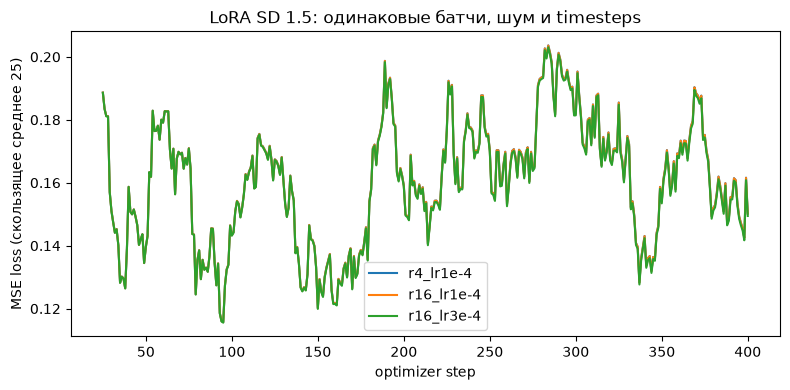

config       loss first50 loss last50 skipped  s/step
r4_lr1e-4          0.1641      0.1627       0   0.733
r16_lr1e-4         0.1641      0.1627       0   0.734
r16_lr3e-4         0.1641      0.1619       0   0.735


In [7]:
# Задание 6. Обучение независимых LoRA-адаптеров с checkpoint (optimizer, scaler, переносимые веса)
import shutil
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers.training_utils import cast_training_params
from diffusers.utils import convert_state_dict_to_diffusers
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

CKPT_ROOT = ARTIFACTS / 'checkpoints'
AMP = DEVICE == 'cuda'
unet, vae, text_encoder = pipe.unet, pipe.vae, pipe.text_encoder
plain_dataset = CaptionedImages(TRAIN_RECORDS, DATA_ROOT, RESOLUTION, flip=False)  # flip делаем сами, от seed шага

# Порядок батчей заранее и одинаков для всех конфигураций: шаг s → одни и те же картинки.
# Шум, t, flip и сэмпл VAE берутся из генератора с seed = f(SEED, s) — тоже одинаковы и не зависят от resume.
n_epochs = -(-MAX_STEPS * TRAIN_BATCH_SIZE // len(plain_dataset)) + 1
order_rng = np.random.default_rng(SEED)
BATCH_ORDER = np.concatenate([order_rng.permutation(len(plain_dataset)) for _ in range(n_epochs)])

def batch_for_step(step):
    idx = BATCH_ORDER[step * TRAIN_BATCH_SIZE:(step + 1) * TRAIN_BATCH_SIZE]
    items = [plain_dataset[int(i)] for i in idx]
    return torch.stack([x['pixel_values'] for x in items]), torch.stack([x['input_ids'] for x in items]), idx.tolist()

def checkpoint_dir(name, step):
    return CKPT_ROOT / name / f'step_{step:04d}'

def latest_checkpoint(name):
    done = [s for s in CHECKPOINT_STEPS if (checkpoint_dir(name, s) / 'COMPLETE').exists()]
    return max(done) if done else None

def save_checkpoint(cfg, step, optimizer, lr_scheduler, scaler, log):
    """Атомарно: пишем во временную папку и переименовываем, чтобы обрыв сессии не оставил полу-checkpoint."""
    final = checkpoint_dir(cfg['name'], step)
    tmp = final.with_name(final.name + '_tmp')
    shutil.rmtree(tmp, ignore_errors=True); tmp.mkdir(parents=True)
    lora_state = {k: v.detach().cpu() for k, v in get_peft_model_state_dict(unet, adapter_name=cfg['name']).items()}
    # Переносимые веса: загружаются в любую SD 1.5 через pipe.load_lora_weights(dir)
    StableDiffusionPipeline.save_lora_weights(tmp, unet_lora_layers=convert_state_dict_to_diffusers(lora_state),
                                              safe_serialization=True)
    # Состояние для точного продолжения обучения
    torch.save({'step': step, 'lora': lora_state, 'optimizer': optimizer.state_dict(),
                'lr_scheduler': lr_scheduler.state_dict(), 'scaler': scaler.state_dict(),
                'log': log, 'config': cfg}, tmp / 'training_state.pt')
    meta = {'config': cfg['name'], 'step': step, 'rank': cfg['rank'], 'alpha': cfg['alpha'], 'lr': cfg['lr'],
            'model_id': MODEL_ID, 'resolution': RESOLUTION, 'scaler_scale': scaler.get_scale(),
            'mean_loss_last_50': round(float(np.mean([r['loss'] for r in log[-50:]])), 5),
            'files': {f.name: hashlib.sha256(f.read_bytes()).hexdigest() for f in sorted(tmp.iterdir())}}
    (tmp / 'checkpoint.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')
    (tmp / 'COMPLETE').write_text('ok')
    shutil.rmtree(final, ignore_errors=True); tmp.rename(final)
    return meta

def summarize(cfg, log, **extra):
    return {'config': cfg['name'], 'rank': cfg['rank'], 'lr': cfg['lr'], 'steps': len(log),
            'skipped_updates': sum(r['skipped'] for r in log),
            'loss_first_50': round(float(np.mean([r['loss'] for r in log[:50]])), 5),
            'loss_last_50': round(float(np.mean([r['loss'] for r in log[-50:]])), 5),
            'sec_per_step': round(float(np.mean([r['sec'] for r in log])), 3),
            'checkpoints': {s: checkpoint_dir(cfg['name'], s).relative_to(ARTIFACTS).as_posix() for s in CHECKPOINT_STEPS},
            **extra}

def train_adapter(cfg):
    name = cfg['name']
    torch.manual_seed(SEED)  # одинаковая инициализация A при одинаковом rank
    unet.add_adapter(make_lora_config(cfg), adapter_name=name)
    unet.set_adapter(name)
    cast_training_params(unet, dtype=torch.float32)  # LoRA в fp32, основа остаётся fp16
    lora_params = [p for p in unet.parameters() if p.requires_grad]
    assert sum(p.numel() for p in lora_params) == cfg['trainable_params'], 'Обучается не только LoRA'

    optimizer = torch.optim.AdamW(lora_params, lr=cfg['lr'], betas=(0.9, 0.999), weight_decay=1e-2)
    lr_scheduler = get_scheduler('cosine', optimizer, num_warmup_steps=TRAIN_SCHEDULE['warmup_steps'],
                                 num_training_steps=MAX_STEPS)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    start, log = 0, []
    resume = latest_checkpoint(name)
    if resume is not None:
        state = torch.load(checkpoint_dir(name, resume) / 'training_state.pt', map_location='cpu', weights_only=False)
        set_peft_model_state_dict(unet, state['lora'], adapter_name=name)
        optimizer.load_state_dict(state['optimizer']); lr_scheduler.load_state_dict(state['lr_scheduler'])
        scaler.load_state_dict(state['scaler'])
        start, log = state['step'], state['log']
        print(f'{name}: продолжаю с checkpoint step {resume}')

    unet.train(); unet.enable_gradient_checkpointing()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t_cfg = time.time()
    for step in range(start, MAX_STEPS):
        t0 = time.time()
        g = torch.Generator().manual_seed(SEED * 100_003 + step)
        pixels, input_ids, idx = batch_for_step(step)
        flip = torch.rand(len(idx), generator=g) < 0.5
        pixels = torch.where(flip[:, None, None, None], pixels.flip(-1), pixels)
        with torch.no_grad():
            posterior = vae.encode(pixels.to(DEVICE, DTYPE)).latent_dist
            eps_vae = torch.randn(posterior.mean.shape, generator=g).to(DEVICE, posterior.mean.dtype)
            latents = (posterior.mean + posterior.std * eps_vae) * vae.config.scaling_factor
            text_embeddings = text_encoder(input_ids.to(DEVICE))[0]
        noise = torch.randn(latents.shape, generator=g).to(DEVICE, latents.dtype)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (len(idx),), generator=g).to(DEVICE)
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=AMP):
            noise_pred = unet(noisy_latents, timesteps, text_embeddings).sample
        loss = F.mse_loss(noise_pred.float(), noise.float())  # ||ε − ε_θ(z_t, t, c)||²
        if not torch.isfinite(loss):
            raise FloatingPointError(f'{name}: loss = {loss.item()} на шаге {step}')

        optimizer.zero_grad(set_to_none=True)
        scale_before = scaler.get_scale()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(lora_params, TRAIN_SCHEDULE['max_grad_norm'])
        scaler.step(optimizer); scaler.update()
        lr_scheduler.step()
        log.append({'step': step + 1, 'loss': round(loss.item(), 6), 'lr': lr_scheduler.get_last_lr()[0],
                    'grad_norm': round(float(grad_norm), 5), 'scale': scaler.get_scale(),
                    'skipped': bool(AMP and scaler.get_scale() < scale_before),  # inf-градиенты → шаг пропущен
                    'timesteps': timesteps.tolist(), 'images': idx, 'sec': round(time.time() - t0, 3)})
        if (step + 1) in CHECKPOINT_STEPS:
            meta = save_checkpoint(cfg, step + 1, optimizer, lr_scheduler, scaler, log)
            print(f"{name}: step {step + 1}/{MAX_STEPS}  loss(50)={meta['mean_loss_last_50']:.4f}  "
                  f"→ {checkpoint_dir(name, step + 1)}")

    unet.disable_gradient_checkpointing(); unet.eval()
    write_jsonl(CKPT_ROOT / name / 'train_log.jsonl', log)
    result = summarize(cfg, log, resumed_from=resume, wall_seconds_this_run=round(time.time() - t_cfg, 1),
                       gpu_peak_memory_gib=round(torch.cuda.max_memory_allocated() / 2**30, 2) if torch.cuda.is_available() else None,
                       lora_l2_norm=round(float(torch.sqrt(sum((p.detach().float() ** 2).sum() for p in lora_params))), 4))

    # Независимость: снимаем адаптер, U-Net снова чистая, основа не изменилась
    unet.delete_adapters(name)
    assert lora_param_count(unet) == 0, f'{name}: адаптер не удалён'
    assert abs(unet_base_checksum(unet) - BASE_UNET_CHECKSUM) < 1e-6 * BASE_UNET_CHECKSUM, 'Основа U-Net изменилась'
    del optimizer, lr_scheduler, scaler, lora_params
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, log

training_results, training_logs = {}, {}
for cfg in LORA_CONFIGS:
    log_path = CKPT_ROOT / cfg['name'] / 'train_log.jsonl'
    if latest_checkpoint(cfg['name']) == MAX_STEPS and log_path.exists():
        log = read_jsonl(log_path)  # уже обучен полностью: не переобучаем
        result = summarize(cfg, log, cached=True)
        print(f"{cfg['name']}: найден финальный checkpoint, обучение пропущено")
    else:
        result, log = train_adapter(cfg)
    training_results[cfg['name']], training_logs[cfg['name']] = result, log

# Контроль одинаковых условий: те же картинки и те же t на каждом шаге во всех конфигурациях
reference = training_logs[LORA_CONFIGS[0]['name']]
for name, log in training_logs.items():
    assert len(log) == MAX_STEPS, f'{name}: {len(log)} шагов вместо {MAX_STEPS}'
    assert [r['images'] for r in log] == [r['images'] for r in reference], f'{name}: другой порядок батчей'
    assert [r['timesteps'] for r in log] == [r['timesteps'] for r in reference], f'{name}: другие timesteps'

save_json('training_summary.json', {'schedule': TRAIN_SCHEDULE, 'results': training_results,
                                    'same_batches_and_timesteps': True})
fig, ax = plt.subplots(figsize=(8, 4))
for name, log in training_logs.items():
    losses = np.array([r['loss'] for r in log])
    window = min(25, len(losses))
    ax.plot(np.arange(window, len(losses) + 1), np.convolve(losses, np.ones(window) / window, 'valid'), label=name)
ax.set_xlabel('optimizer step'); ax.set_ylabel(f'MSE loss (скользящее среднее {window})')
ax.set_title('LoRA SD 1.5: одинаковые батчи, шум и timesteps'); ax.legend(); fig.tight_layout()
fig.savefig(ARTIFACTS / 'training_loss.png', dpi=120); plt.show()
print(f"{'config':12s} {'loss first50':>12s} {'loss last50':>11s} {'skipped':>7s} {'s/step':>7s}")
for r in training_results.values():
    print(f"{r['config']:12s} {r['loss_first_50']:>12.4f} {r['loss_last_50']:>11.4f} "
          f"{r['skipped_updates']:>7d} {r['sec_per_step']:>7.3f}")

### Задание 7. Признаки CLIP для независимой оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings.

**Результат.** Проверяемое состояние «Признаки CLIP для независимой оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings» и его результат доступен следующему этапу.

In [8]:
# Задание 7. Независимый CLIP: нормализованные текстовые и визуальные embeddings
from transformers import CLIPModel, CLIPProcessor

# Судья ≠ генератор: SD 1.5 использует text encoder CLIP ViT-L/14, для оценки берём другую модель CLIP
CLIP_ID = os.getenv('CV_CLIP_MODEL', 'openai/clip-vit-base-patch32')
assert CLIP_ID != 'openai/clip-vit-large-patch14', 'Оценщик совпадает с text encoder SD 1.5'
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)
clip_model.requires_grad_(False)

def _features(output):
    # transformers 5 возвращает объект с проекцией в pooler_output, 4.x — сразу тензор
    return output if torch.is_tensor(output) else output.pooler_output

@torch.inference_mode()
def embed_texts(texts, batch_size=32):
    """Тексты → L2-нормализованные embeddings [N, D] (float32, CPU)."""
    chunks = []
    for i in range(0, len(texts), batch_size):
        inputs = clip_processor(text=list(texts[i:i + batch_size]), padding=True, truncation=True,
                                return_tensors='pt').to(DEVICE)
        chunks.append(F.normalize(_features(clip_model.get_text_features(**inputs)).float(), dim=-1).cpu())
    return torch.cat(chunks)

@torch.inference_mode()
def embed_images(images, batch_size=16):
    """Пути или PIL → L2-нормализованные embeddings [N, D] (float32, CPU)."""
    chunks = []
    for i in range(0, len(images), batch_size):
        batch = []
        for item in images[i:i + batch_size]:
            if isinstance(item, Image.Image):
                batch.append(item.convert('RGB'))
            else:
                with Image.open(item) as image:
                    batch.append(ImageOps.exif_transpose(image).convert('RGB'))
        inputs = clip_processor(images=batch, return_tensors='pt').to(DEVICE)
        chunks.append(F.normalize(_features(clip_model.get_image_features(**inputs)).float(), dim=-1).cpu())
    return torch.cat(chunks)

# Embeddings отложенных prompts — понадобятся в задании 9 для текстового сходства
eval_text_emb = embed_texts(EVAL_PROMPTS)

# Проверки на реальных train-фото (их embeddings в задании 8 посчитаем для всех изображений)
probe_paths = [DATA_ROOT / r['file_name'] for r in TRAIN_RECORDS]
probe_img_emb = embed_images(probe_paths)
norms = torch.cat([eval_text_emb.norm(dim=-1), probe_img_emb.norm(dim=-1)])
repeat_max_diff = (embed_images(probe_paths[:4]) - probe_img_emb[:4]).abs().max().item()

# 1) Zero-shot: CLIP должен узнать бабочку на каждом train-фото
labels = ['butterfly', 'moth', 'bird', 'flower', 'dog', 'car', 'leaf']
label_emb = embed_texts([f'a photo of a {label}' for label in labels])
zero_shot = (probe_img_emb @ label_emb.T).argmax(dim=1)
zero_shot_acc = (zero_shot == labels.index('butterfly')).float().mean().item()
# 2) Своя подпись ближе чужих: косинус на диагонали против вне диагонали
caption_emb = embed_texts([r['text'] for r in TRAIN_RECORDS])
sim = probe_img_emb @ caption_emb.T
matched, mismatched = sim.diag().mean().item(), sim[~torch.eye(len(sim), dtype=bool)].mean().item()
retrieval_top1 = (sim.argmax(dim=1) == torch.arange(len(sim))).float().mean().item()

clip_info = {
    'model_id': CLIP_ID, 'generator_text_encoder': 'openai/clip-vit-large-patch14 (внутри SD 1.5)',
    'embedding_dim': eval_text_emb.shape[1], 'normalization': 'L2, cosine = dot product',
    'logit_scale': round(clip_model.logit_scale.exp().item(), 2),
    'norm_min': round(norms.min().item(), 6), 'norm_max': round(norms.max().item(), 6),
    'repeat_max_abs_diff': repeat_max_diff,
    'zero_shot_labels': labels, 'zero_shot_butterfly_acc': round(zero_shot_acc, 3),
    'zero_shot_errors': [{'file': r['file_name'], 'predicted': labels[k]}
                         for r, k in zip(TRAIN_RECORDS, zero_shot.tolist()) if k != labels.index('butterfly')],
    'own_caption_cos': round(matched, 4), 'other_caption_cos': round(mismatched, 4),
    'caption_retrieval_top1': round(retrieval_top1, 3),
}
torch.save({'prompts': EVAL_PROMPTS, 'embeddings': eval_text_emb, 'model_id': CLIP_ID},
           ARTIFACTS / 'clip_eval_prompts.pt')
save_json('clip_info.json', clip_info)
print(json.dumps(clip_info, ensure_ascii=False, indent=2))

assert abs(clip_info['norm_min'] - 1) < 1e-4 and abs(clip_info['norm_max'] - 1) < 1e-4, 'Embeddings не нормализованы'
assert repeat_max_diff < 1e-3, 'CLIP embeddings не детерминированы'
assert matched > mismatched, 'Своя подпись не ближе чужих: CLIP-признаки не различают изображения'
print(f'OK: {CLIP_ID}, dim={clip_info["embedding_dim"]}, бабочка распознана на {zero_shot_acc:.0%} train-фото')

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

{
  "model_id": "openai/clip-vit-base-patch32",
  "generator_text_encoder": "openai/clip-vit-large-patch14 (внутри SD 1.5)",
  "embedding_dim": 512,
  "normalization": "L2, cosine = dot product",
  "logit_scale": 100.0,
  "norm_min": 1.0,
  "norm_max": 1.0,
  "repeat_max_abs_diff": 0.00033470243215560913,
  "zero_shot_labels": [
    "butterfly",
    "moth",
    "bird",
    "flower",
    "dog",
    "car",
    "leaf"
  ],
  "zero_shot_butterfly_acc": 0.857,
  "zero_shot_errors": [
    {
      "file": "commons_02.jpg",
      "predicted": "flower"
    },
    {
      "file": "commons_06.jpg",
      "predicted": "moth"
    },
    {
      "file": "commons_24.jpg",
      "predicted": "car"
    },
    {
      "file": "commons_26.jpg",
      "predicted": "moth"
    }
  ],
  "own_caption_cos": 0.299,
  "other_caption_cos": 0.2704,
  "caption_retrieval_top1": 0.321
}
OK: openai/clip-vit-base-patch32, dim=512, бабочка распознана на 86% train-фото


### Задание 8. Поиск ближайших обучающих изображений

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки.

**Результат.** Проверяемое состояние «Поиск ближайших обучающих изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки» и его результат доступен следующему этапу.

In [9]:
# Задание 8. Embeddings реальных train-изображений, поиск ближайшего и фиксированный набор checkpoints
import io

# 1) Train embeddings в том виде, в каком их видела модель: центр-кроп R×R и его зеркало (flip в обучении)
train_view = CaptionedImages(TRAIN_RECORDS, DATA_ROOT, RESOLUTION, flip=False).transform

def training_view(path, mirror=False):
    with Image.open(path) as image:
        pixels = train_view(ImageOps.exif_transpose(image).convert('RGB'))  # [-1, 1]
    image = transforms.functional.to_pil_image((pixels + 1) / 2)
    return ImageOps.mirror(image) if mirror else image

train_files = [r['file_name'] for r in TRAIN_RECORDS]
train_paths = [DATA_ROOT / f for f in train_files]
train_emb = embed_images([training_view(p) for p in train_paths])               # [N, D]
train_emb_mirror = embed_images([training_view(p, mirror=True) for p in train_paths])

def nearest_train(query_emb):
    """Для каждого query: индекс ближайшего train-фото и косинус (максимум по оригиналу и зеркалу)."""
    sim = torch.maximum(query_emb @ train_emb.T, query_emb @ train_emb_mirror.T)  # [Q, N]
    cos, idx = sim.max(dim=1)
    return idx, cos, sim

# 2) Шкала: насколько похожи друг на друга РАЗНЫЕ реальные фото бабочек
train_sim = torch.maximum(train_emb @ train_emb.T, train_emb @ train_emb_mirror.T)
train_sim.fill_diagonal_(-1)
nn_between_train = train_sim.max(dim=1).values
# Генерация ближе к train-фото, чем любые два разных train-фото друг к другу, — кандидат в копию
COPY_THRESHOLD = round(nn_between_train.max().item(), 4)

# 3) Положительный контроль: слегка искажённая копия train-фото должна найти саму себя и пройти порог
def near_copy(path):
    image = training_view(path).resize((RESOLUTION * 3 // 4,) * 2).rotate(3)
    buffer = io.BytesIO(); image.save(buffer, format='JPEG', quality=70)
    return Image.open(io.BytesIO(buffer.getvalue())).convert('RGB')

copy_idx, copy_cos, _ = nearest_train(embed_images([near_copy(p) for p in train_paths]))
copy_found = (copy_idx == torch.arange(len(train_paths))).float().mean().item()
copy_flagged = (copy_cos > COPY_THRESHOLD).float().mean().item()

# 4) Уровень baseline: насколько генерации SD без LoRA уже похожи на train
baseline_emb = embed_images([ARTIFACTS / r['file'] for r in baseline_rows])
base_idx, base_cos, _ = nearest_train(baseline_emb)

# 5) Фиксированный набор моделей для оценки: baseline + каждый checkpoint каждой конфигурации.
# Оцениваются ВСЕ checkpoints, выбор лучшего по отложенным prompts не делается.
def verify_checkpoint(directory):
    meta = json.loads((directory / 'checkpoint.json').read_text(encoding='utf-8'))
    for file_name, expected in meta['files'].items():
        actual = hashlib.sha256((directory / file_name).read_bytes()).hexdigest()
        assert actual == expected, f'{directory / file_name}: sha256 не совпадает'
    return meta

EVAL_MODELS = [{'tag': 'baseline', 'config': None, 'step': 0, 'rank': None, 'lr': None, 'lora_dir': None}]
for cfg in LORA_CONFIGS:
    for step in CHECKPOINT_STEPS:
        directory = checkpoint_dir(cfg['name'], step)
        assert (directory / 'COMPLETE').exists(), f'Нет checkpoint {directory}'
        meta = verify_checkpoint(directory)
        EVAL_MODELS.append({'tag': f"{cfg['name']}_step{step:04d}", 'config': cfg['name'], 'step': step,
                            'rank': cfg['rank'], 'lr': cfg['lr'],
                            'lora_dir': directory.relative_to(ARTIFACTS).as_posix(),
                            'lora_sha256': meta['files']['pytorch_lora_weights.safetensors'],
                            'train_loss_last_50': meta['mean_loss_last_50']})

torch.save({'files': train_files, 'embeddings': train_emb, 'embeddings_mirror': train_emb_mirror,
            'model_id': CLIP_ID, 'view': f'Resize+CenterCrop {RESOLUTION}'}, ARTIFACTS / 'clip_train_embeddings.pt')
nearest_reference = {
    'clip_model': CLIP_ID, 'n_train': len(train_files),
    'train_to_other_train_nn_cos': {'min': round(nn_between_train.min().item(), 4),
                                    'mean': round(nn_between_train.mean().item(), 4),
                                    'max': COPY_THRESHOLD},
    'copy_threshold': COPY_THRESHOLD,
    'copy_threshold_rule': 'max косинуса между разными train-фото (с учётом зеркала)',
    'positive_control': {'distortion': 'resize 0.75, rotate 3°, JPEG q70',
                         'self_retrieved_top1': round(copy_found, 3), 'above_threshold': round(copy_flagged, 3),
                         'cos_min': round(copy_cos.min().item(), 4)},
    'baseline_nearest_train_cos': {'mean': round(base_cos.mean().item(), 4), 'max': round(base_cos.max().item(), 4),
                                   'n_above_threshold': int((base_cos > COPY_THRESHOLD).sum())},
    'closest_train_pair': [train_files[i] for i in divmod(int(train_sim.argmax()), len(train_files))],
}
save_json('nearest_train_reference.json', nearest_reference)
save_json('eval_checkpoints.json', {'models': EVAL_MODELS, 'eval_spec_sha256': EVAL_SPEC_SHA256,
                                    'selection': 'все checkpoints, без выбора по eval prompts'})

print(json.dumps(nearest_reference, ensure_ascii=False, indent=2))
print(f'\nНабор для оценки ({len(EVAL_MODELS)} моделей × {len(EVAL_PROMPTS) * len(EVAL_SEEDS)} генераций):')
for m in EVAL_MODELS:
    print(f"  {m['tag']:22s} rank={m['rank']}  lr={m['lr']}  {m['lora_dir'] or '— без LoRA'}")

assert copy_found >= 0.9, f'Поиск ближайшего находит искажённую копию лишь в {copy_found:.0%} случаев'
if copy_flagged < 1.0:  # порог задан данными: два очень похожих train-фото поднимают его выше части копий
    print(f'Внимание: порог {COPY_THRESHOLD} ловит {copy_flagged:.0%} искажённых копий — учитывать при выводах')
assert len(EVAL_MODELS) == 1 + len(LORA_CONFIGS) * len(CHECKPOINT_STEPS)

{
  "clip_model": "openai/clip-vit-base-patch32",
  "n_train": 28,
  "train_to_other_train_nn_cos": {
    "min": 0.7198,
    "mean": 0.8392,
    "max": 0.9022
  },
  "copy_threshold": 0.9022,
  "copy_threshold_rule": "max косинуса между разными train-фото (с учётом зеркала)",
  "positive_control": {
    "distortion": "resize 0.75, rotate 3°, JPEG q70",
    "self_retrieved_top1": 1.0,
    "above_threshold": 0.929,
    "cos_min": 0.8351
  },
  "baseline_nearest_train_cos": {
    "mean": 0.7408,
    "max": 0.864,
    "n_above_threshold": 0
  },
  "closest_train_pair": [
    "commons_15.jpg",
    "commons_25.jpg"
  ]
}

Набор для оценки (7 моделей × 32 генераций):
  baseline               rank=None  lr=None  — без LoRA
  r4_lr1e-4_step0200     rank=4  lr=0.0001  checkpoints/r4_lr1e-4/step_0200
  r4_lr1e-4_step0400     rank=4  lr=0.0001  checkpoints/r4_lr1e-4/step_0400
  r16_lr1e-4_step0200    rank=16  lr=0.0001  checkpoints/r16_lr1e-4/step_0200
  r16_lr1e-4_step0400    rank=16  lr=0.0001  

### Задание 9. Парные генерации и измеримые показатели

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA.

**Результат.** Проверяемое состояние «Парные генерации и измеримые показатели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA» и его результат доступен следующему этапу.

baseline               32 изображений, новых 0


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


r4_lr1e-4_step0200     32 изображений, новых 0


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


r4_lr1e-4_step0400     32 изображений, новых 0


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


... (3 outputs left out)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


r16_lr3e-4_step0200    32 изображений, новых 0


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


r16_lr3e-4_step0400    32 изображений, новых 0

model                   clipT  ΔclipT    div nnTrain   ΔnnT  nnMax copy uniqNN  Δpix
baseline                0.323  +0.000  0.144   0.741 +0.000  0.864    0      8   0.0
r4_lr1e-4_step0200      0.329  +0.007  0.125   0.752 +0.011  0.851    0      7  19.9
r4_lr1e-4_step0400      0.326  +0.003  0.124   0.754 +0.013  0.876    0      6  20.7
r16_lr1e-4_step0200     0.329  +0.006  0.135   0.750 +0.009  0.915    1      7  21.4
r16_lr1e-4_step0400     0.333  +0.010  0.130   0.748 +0.007  0.862    0      8  23.0
r16_lr3e-4_step0200     0.335  +0.012  0.128   0.759 +0.018  0.903    1      7  28.9
r16_lr3e-4_step0400     0.334  +0.011  0.132   0.745 +0.004  0.874    0      8  29.6

baseline после снятия всех LoRA: mean |Δpix| = 0.000; порог копии = 0.9022


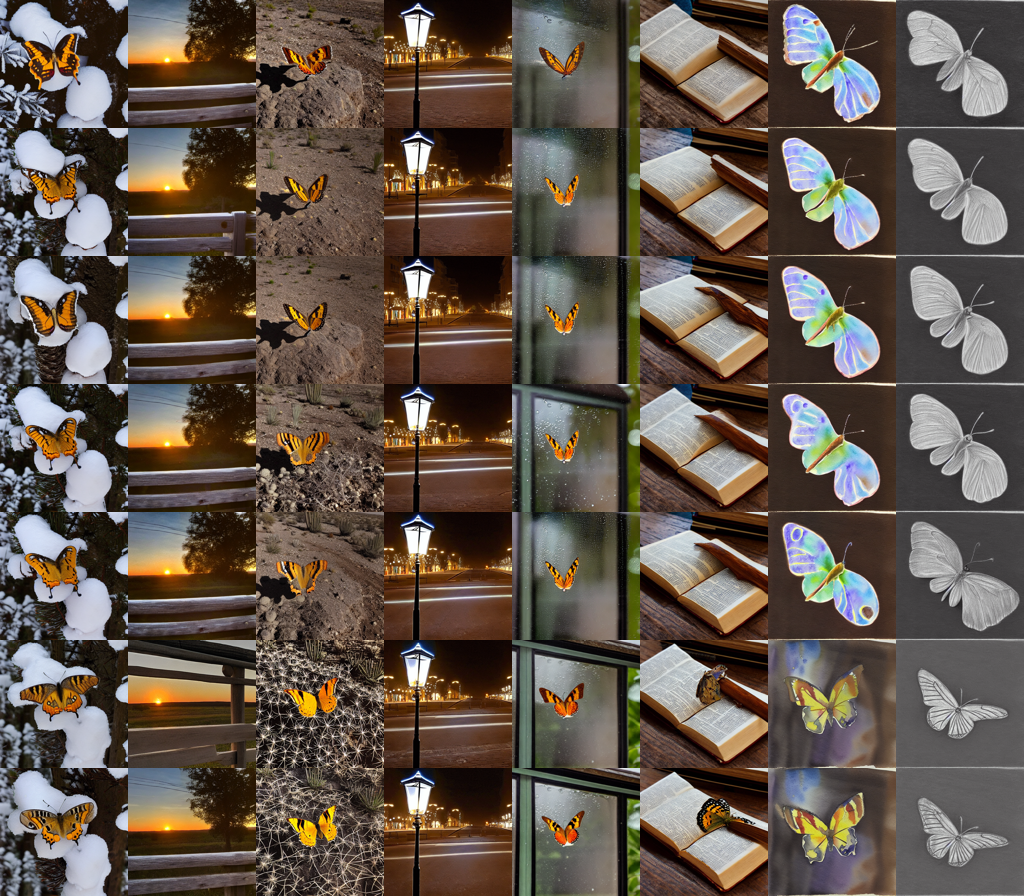

In [10]:
# Задание 9. Парные генерации (одинаковые prompts/seeds) и измеримые показатели
import csv
from itertools import combinations

N_BOOT = 2000
boot_rng = np.random.default_rng(SEED)

def bootstrap_ci(values):
    """95% CI среднего по парам prompt/seed (бутстрэп)."""
    values = np.asarray(values, dtype=float)
    means = values[boot_rng.integers(0, len(values), (N_BOOT, len(values)))].mean(axis=1)
    return [round(float(np.percentile(means, 2.5)), 4), round(float(np.percentile(means, 97.5)), 4)]

def load_rgb(path):
    with Image.open(path) as image:
        return np.asarray(image.convert('RGB'), dtype=np.float32)

# 1) Генерации: baseline без LoRA, затем каждый checkpoint по очереди тем же generate_set
generations, gen_seconds = {}, {}
for m in EVAL_MODELS:
    if m['lora_dir'] is None:
        assert lora_param_count(pipe.unet) == 0, 'Baseline должен генерироваться без LoRA'
        generations[m['tag']], seconds = generate_set(pipe, m['tag'])
    else:
        pipe.load_lora_weights(ARTIFACTS / m['lora_dir'], adapter_name=m['tag'])
        pipe.set_adapters([m['tag']])
        assert lora_param_count(pipe.unet) > 0, f"{m['tag']}: LoRA не загрузилась"
        generations[m['tag']], seconds = generate_set(pipe, m['tag'])
        pipe.delete_adapters(m['tag'])
        assert lora_param_count(pipe.unet) == 0, f"{m['tag']}: LoRA не снята"
    gen_seconds[m['tag']] = round(float(np.mean(seconds)), 2) if seconds else None
    print(f"{m['tag']:22s} {len(generations[m['tag']])} изображений, новых {len(seconds)}")

# Контроль: после снятия всех адаптеров модель снова даёт ту же baseline-картинку
generator = torch.Generator(device=DEVICE).manual_seed(EVAL_SEEDS[0])
with torch.inference_mode():
    recheck = pipe(EVAL_PROMPTS[0], generator=generator, num_inference_steps=INFERENCE['num_inference_steps'],
                   guidance_scale=INFERENCE['guidance_scale'],
                   height=INFERENCE['height'], width=INFERENCE['width']).images[0]
baseline_recheck_diff = float(np.abs(load_rgb(ARTIFACTS / generations['baseline'][0]['file'])
                                     - np.asarray(recheck, np.float32)).mean())
assert baseline_recheck_diff < 2.0, f'После снятия LoRA baseline изменился: mean |Δ| = {baseline_recheck_diff:.2f}'

# 2) Метрики по каждой картинке: CLIP-сходство с prompt, ближайший train, парные отличия от baseline
image_emb = {tag: embed_images([ARTIFACTS / r['file'] for r in rows]) for tag, rows in generations.items()}
prompt_index = {p: i for i, p in enumerate(EVAL_PROMPTS)}
per_image = []
for tag, rows in generations.items():
    emb = image_emb[tag]
    text_cos = (emb * eval_text_emb[[prompt_index[r['prompt']] for r in rows]]).sum(dim=1)
    nn_idx, nn_cos, _ = nearest_train(emb)
    base_emb = image_emb['baseline']
    for k, r in enumerate(rows):
        base_row = generations['baseline'][k]
        assert (base_row['prompt'], base_row['seed']) == (r['prompt'], r['seed']), 'Пары prompt/seed не совпадают'
        per_image.append({
            'model': tag, 'prompt_id': r['prompt_id'], 'seed': r['seed'], 'file': r['file'],
            'clip_text': round(text_cos[k].item(), 4),
            'nearest_train': train_files[nn_idx[k]], 'nearest_train_cos': round(nn_cos[k].item(), 4),
            'copy_candidate': bool(nn_cos[k] > COPY_THRESHOLD),
            'cos_to_baseline_pair': round(float(emb[k] @ base_emb[k]), 4),
            'pixel_diff_vs_baseline': round(float(np.abs(load_rgb(ARTIFACTS / r['file'])
                                                         - load_rgb(ARTIFACTS / base_row['file'])).mean()), 2),
        })

# 3) Разнообразие: 1 − средний косинус между картинками одного prompt с разными seeds
def diversity(tag):
    emb, rows = image_emb[tag], generations[tag]
    per_prompt = []
    for p in EVAL_PROMPTS:
        ids = [k for k, r in enumerate(rows) if r['prompt'] == p]
        if len(ids) > 1:
            per_prompt.append(np.mean([1 - float(emb[a] @ emb[b]) for a, b in combinations(ids, 2)]))
    return float(np.mean(per_prompt)) if per_prompt else None

# 4) Сводка по моделям; дельты считаются ПАРНО к baseline (тот же prompt и seed)
base_text = np.array([r['clip_text'] for r in per_image if r['model'] == 'baseline'])
base_nn = np.array([r['nearest_train_cos'] for r in per_image if r['model'] == 'baseline'])
summary = []
for m in EVAL_MODELS:
    rows = [r for r in per_image if r['model'] == m['tag']]
    text, nn = np.array([r['clip_text'] for r in rows]), np.array([r['nearest_train_cos'] for r in rows])
    div = diversity(m['tag'])
    summary.append({
        'model': m['tag'], 'config': m['config'], 'step': m['step'], 'rank': m['rank'], 'lr': m['lr'],
        'clip_text_mean': round(float(text.mean()), 4),
        'clip_text_delta_vs_baseline': round(float((text - base_text).mean()), 4),
        'clip_text_delta_ci95': bootstrap_ci(text - base_text) if m['lora_dir'] else None,
        'diversity': round(div, 4) if div is not None else None,
        'nearest_train_cos_mean': round(float(nn.mean()), 4),
        'nearest_train_cos_max': round(float(nn.max()), 4),
        'nearest_train_delta_vs_baseline': round(float((nn - base_nn).mean()), 4),
        'nearest_train_delta_ci95': bootstrap_ci(nn - base_nn) if m['lora_dir'] else None,
        'n_copy_candidates': sum(r['copy_candidate'] for r in rows),
        'n_unique_nearest_train': len({r['nearest_train'] for r in rows}),
        'pixel_diff_vs_baseline': round(float(np.mean([r['pixel_diff_vs_baseline'] for r in rows])), 2),
        'sec_per_image': gen_seconds[m['tag']],
        'train_loss_last_50': m.get('train_loss_last_50'),
    })

write_jsonl(ARTIFACTS / 'generation_metrics.jsonl', per_image)
save_json('model_metrics.json', {'clip_model': CLIP_ID, 'copy_threshold': COPY_THRESHOLD,
                                 'eval_spec_sha256': EVAL_SPEC_SHA256, 'n_pairs': len(base_text),
                                 'baseline_recheck_pixel_diff': round(baseline_recheck_diff, 3),
                                 'models': summary})
with open(ARTIFACTS / 'model_metrics.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(summary[0]))
    writer.writeheader(); writer.writerows(summary)

# 5) Визуальное сравнение: строки — модели, столбцы — prompts (первый seed)
thumb = 128
grid = Image.new('RGB', (thumb * len(EVAL_PROMPTS), thumb * len(EVAL_MODELS)), 'white')
for row_i, m in enumerate(EVAL_MODELS):
    for r in generations[m['tag']]:
        if r['seed'] == EVAL_SEEDS[0]:
            with Image.open(ARTIFACTS / r['file']) as image:
                grid.paste(image.convert('RGB').resize((thumb, thumb)),
                           (int(r['prompt_id'][1:]) * thumb, row_i * thumb))
grid.save(ARTIFACTS / 'comparison_grid.png')

print(f"\n{'model':22s} {'clipT':>6s} {'ΔclipT':>7s} {'div':>6s} {'nnTrain':>7s} {'ΔnnT':>6s} "
      f"{'nnMax':>6s} {'copy':>4s} {'uniqNN':>6s} {'Δpix':>5s}")
for s in summary:
    print(f"{s['model']:22s} {s['clip_text_mean']:>6.3f} {s['clip_text_delta_vs_baseline']:>+7.3f} "
          f"{(s['diversity'] or 0):>6.3f} {s['nearest_train_cos_mean']:>7.3f} {s['nearest_train_delta_vs_baseline']:>+6.3f} "
          f"{s['nearest_train_cos_max']:>6.3f} {s['n_copy_candidates']:>4d} {s['n_unique_nearest_train']:>6d} "
          f"{s['pixel_diff_vs_baseline']:>5.1f}")
print(f'\nbaseline после снятия всех LoRA: mean |Δpix| = {baseline_recheck_diff:.3f}; порог копии = {COPY_THRESHOLD}')
display(grid)  # строки: baseline, затем checkpoints в порядке EVAL_MODELS; столбцы: p00…p07

### Задание 10. Слепая таблица оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов.

**Результат.** Проверяемое состояние «Слепая таблица оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов» и его результат доступен следующему этапу.

In [14]:
# Задание 10. Слепая таблица для ручной оценки реальными экспертами
from itertools import groupby

BLIND_DIR = ARTIFACTS / 'blind'               # отдаётся экспертам
KEY_PATH = ARTIFACTS / 'blind_key.json'       # НЕ отдаётся экспертам: связь item_id → модель
BLIND_SEEDS = EVAL_SEEDS[:2]                  # 7 моделей × 8 prompts × 2 seeds — посильный объём для человека
N_REPEATS = 8                                 # повторные показы для проверки согласованности эксперта
RATING_COLUMNS = ['prompt_match_1to5', 'quality_1to5', 'looks_copied_yes_no', 'comment']

blind_rng = np.random.default_rng(SEED + 10)
items = [{'model': r['model'], 'prompt_id': r['prompt_id'], 'seed': r['seed'], 'source_file': r['file']}
         for r in per_image if r['seed'] in BLIND_SEEDS]
# Повторы: те же изображения под другими id, чтобы измерить test-retest согласованность
repeat_ids = blind_rng.choice(len(items), size=N_REPEATS, replace=False)
items += [{**items[i], 'repeat_of': int(i)} for i in repeat_ids]
order = blind_rng.permutation(len(items))
items = [items[i] for i in order]

shutil.rmtree(BLIND_DIR, ignore_errors=True)
(BLIND_DIR / 'images').mkdir(parents=True)
item_codes = blind_rng.choice(16**6, size=len(items), replace=False)
key_rows, sheet_rows = [], []
for position, (item, code) in enumerate(zip(items, item_codes), start=1):
    item_id = f'{code:06x}'  # случайный код без информации о модели, prompt и порядке
    with Image.open(ARTIFACTS / item['source_file']) as image:
        clean = Image.new('RGB', image.size); clean.paste(image.convert('RGB'))  # без PNG-метаданных
    image_path = BLIND_DIR / 'images' / f'{item_id}.png'
    clean.save(image_path)
    prompt = EVAL_PROMPTS[int(item['prompt_id'][1:])]
    sheet_rows.append({'position': position, 'item_id': item_id, 'image': f'images/{item_id}.png',
                       'prompt': prompt, 'rater_id': '', **{c: '' for c in RATING_COLUMNS}})
    key_rows.append({'item_id': item_id, **item, 'sha256': hashlib.sha256(image_path.read_bytes()).hexdigest()})

with open(BLIND_DIR / 'blind_ratings.csv', 'w', newline='', encoding='utf-8-sig') as f:  # BOM — для Excel
    writer = csv.DictWriter(f, fieldnames=list(sheet_rows[0]))
    writer.writeheader(); writer.writerows(sheet_rows)
(BLIND_DIR / 'INSTRUCTIONS.md').write_text(f"""# Слепая оценка генераций

Каждая строка `blind_ratings.csv` — одно изображение из `images/` и текст запроса, по которому оно получено.
Модель, настройки и порядок генерации скрыты. Оценивайте каждое изображение независимо, в указанном порядке.

- `rater_id` — ваш псевдоним (одинаковый во всех строках).
- `prompt_match_1to5` — насколько изображение соответствует запросу: 1 — не соответствует, 5 — полностью.
- `quality_1to5` — правдоподобие и качество изображения бабочки: 1 — артефакты/искажения, 5 — без дефектов.
- `looks_copied_yes_no` — `yes`, если изображение выглядит как почти точная копия одного из
  эталонных фото (папка с эталонами выдаётся отдельно), иначе `no`.
- `comment` — по желанию: что именно не так.

Всего {len(sheet_rows)} изображений. Некоторые могут повторяться — оценивайте их заново, не сверяясь с прошлой оценкой.
""", encoding='utf-8')
save_json('blind_key.json', {'note': 'не передавать экспертам', 'n_items': len(key_rows),
                             'blind_seeds': BLIND_SEEDS, 'n_repeats': N_REPEATS, 'items': key_rows})

# Проверки слепоты и баланса
sheet_text = (BLIND_DIR / 'blind_ratings.csv').read_text(encoding='utf-8-sig')
leaked = [m['tag'] for m in EVAL_MODELS if m['tag'] in sheet_text] + \
         [w for w in ('baseline', 'lora', 'rank', 'step_') if w in sheet_text.lower()]
assert not leaked, f'В таблице для экспертов есть сведения о модели: {leaked}'
assert all(row[c] == '' for row in sheet_rows for c in RATING_COLUMNS + ['rater_id']), 'Оценки должны быть пустыми'
assert len({row['item_id'] for row in sheet_rows}) == len(sheet_rows), 'Повторяющиеся item_id'
assert {p.name for p in (BLIND_DIR / 'images').iterdir()} == {f"{row['item_id']}.png" for row in sheet_rows}
counts = Counter(k['model'] for k in key_rows if 'repeat_of' not in k)
assert len(set(counts.values())) == 1, f'Модели представлены неравномерно: {counts}'
models_in_order = [k['model'] for k in key_rows]
longest_run = max(len(list(g)) for _, g in groupby(models_in_order))
mean_position = {tag: round(float(np.mean([i for i, k in enumerate(key_rows, 1) if k['model'] == tag])), 1)
                 for tag in counts}

RATINGS_DIR = ARTIFACTS / 'blind_ratings'  # заполненные оценки экспертов; перезапуск этой ячейки их не удаляет
RATINGS_DIR.mkdir(parents=True, exist_ok=True)

def analyze_blind_ratings():
    """Раскрывает ключ по заполненным оценкам всех экспертов. Пока оценок нет — возвращает None, ничего не выдумывает."""
    key = {k['item_id']: k for k in json.loads(KEY_PATH.read_text(encoding='utf-8'))['items']}
    rated = []
    for path in sorted(RATINGS_DIR.glob('ratings_*.csv')):
        with open(path, encoding='utf-8-sig') as f:
            rated += [r for r in csv.DictReader(f) if r['prompt_match_1to5'].strip()]
    if not rated:
        return None
    unknown = [r['item_id'] for r in rated if r['item_id'] not in key]
    assert not unknown, f'Оценки для неизвестных item_id (ключ пересоздан?): {unknown[:5]}'
    by_model = {}
    for r in rated:
        by_model.setdefault(key[r['item_id']]['model'], []).append(r)
    per_model = {model: {'n': len(rs), 'raters': len({r['rater_id'] for r in rs}),
                         'prompt_match': round(float(np.mean([float(r['prompt_match_1to5']) for r in rs])), 2),
                         'quality': round(float(np.mean([float(r['quality_1to5']) for r in rs])), 2),
                         'copied_share': round(float(np.mean([r['looks_copied_yes_no'] == 'yes' for r in rs])), 3)}
                 for model, rs in sorted(by_model.items(), key=lambda kv: [m['tag'] for m in EVAL_MODELS].index(kv[0]))}
    # Test-retest: одно и то же изображение, показанное эксперту дважды под разными id
    pairs = {}
    for r in rated:
        pairs.setdefault((r['rater_id'], key[r['item_id']]['source_file']), []).append(r)
    repeats = [rs[:2] for rs in pairs.values() if len(rs) > 1]
    consistency = None
    if repeats:
        consistency = {'n_pairs': len(repeats),
                       'prompt_match_mean_abs_diff': round(float(np.mean(
                           [abs(float(a['prompt_match_1to5']) - float(b['prompt_match_1to5'])) for a, b in repeats])), 2),
                       'quality_mean_abs_diff': round(float(np.mean(
                           [abs(float(a['quality_1to5']) - float(b['quality_1to5'])) for a, b in repeats])), 2),
                       'copied_agreement': round(float(np.mean(
                           [a['looks_copied_yes_no'] == b['looks_copied_yes_no'] for a, b in repeats])), 3)}
    return {'n_ratings': len(rated), 'raters': sorted({r['rater_id'] for r in rated}),
            'per_model': per_model, 'repeat_consistency': consistency}

blind_summary = {'n_items': len(sheet_rows), 'n_unique_images': len(sheet_rows) - N_REPEATS, 'n_repeats': N_REPEATS,
                 'per_model': dict(counts), 'longest_same_model_run': longest_run,
                 'mean_position_by_model': mean_position, 'rating_columns': RATING_COLUMNS,
                 'files': {'for_experts': [f'{BLIND_DIR.name}/blind_ratings.csv', f'{BLIND_DIR.name}/INSTRUCTIONS.md',
                                           f'{BLIND_DIR.name}/images/'], 'hidden_key': KEY_PATH.name},
                 'ratings_filled': analyze_blind_ratings() is not None}
save_json('blind_summary.json', blind_summary)
print(json.dumps(blind_summary, ensure_ascii=False, indent=2))
print(f'\nЭкспертам отдать папку {BLIND_DIR} и эталонные фото {DATA_ROOT}; {KEY_PATH.name} не передавать.')
print('Оценки вводятся в следующей ячейке; analyze_blind_ratings() раскроет ключ и посчитает средние по моделям.')

{
  "n_items": 120,
  "n_unique_images": 112,
  "n_repeats": 8,
  "per_model": {
    "r16_lr1e-4_step0400": 16,
    "r4_lr1e-4_step0200": 16,
    "baseline": 16,
    "r4_lr1e-4_step0400": 16,
    "r16_lr1e-4_step0200": 16,
    "r16_lr3e-4_step0200": 16,
    "r16_lr3e-4_step0400": 16
  },
  "longest_same_model_run": 3,
  "mean_position_by_model": {
    "r16_lr1e-4_step0400": 67.7,
    "r4_lr1e-4_step0200": 50.6,
    "baseline": 58.6,
    "r4_lr1e-4_step0400": 58.1,
    "r16_lr1e-4_step0200": 59.1,
    "r16_lr3e-4_step0200": 65.6,
    "r16_lr3e-4_step0400": 63.8
  },
  "rating_columns": [
    "prompt_match_1to5",
    "quality_1to5",
    "looks_copied_yes_no",
    "comment"
  ],
  "files": {
    "for_experts": [
      "blind/blind_ratings.csv",
      "blind/INSTRUCTIONS.md",
      "blind/images/"
    ],
    "hidden_key": "blind_key.json"
  },
  "ratings_filled": true
}

Экспертам отдать папку artifacts\lab13\blind и эталонные фото data\lab13; blind_key.json не передавать.
Оценки вводятся 

In [15]:
# Задание 10 (продолжение). Ввод слепых оценок прямо в ноутбуке.
# Каждый эксперт вводит свой псевдоним; оценки автосохраняются в artifacts/lab13/blind_ratings/ratings_<псевдоним>.csv.
# Можно прервать и продолжить позже: форма откроется на первом неоценённом изображении.
import ipywidgets as widgets
from IPython.display import clear_output

with open(BLIND_DIR / 'blind_ratings.csv', encoding='utf-8-sig') as f:
    TEMPLATE_ROWS = list(csv.DictReader(f))
FIELDS = list(TEMPLATE_ROWS[0])

# Эталонные train-фото для решения «похоже на копию» (информации о моделях здесь нет)
REFERENCE_SHEET = BLIND_DIR / 'reference_train.png'
if not REFERENCE_SHEET.exists():
    cols, thumb = 7, 120
    sheet = Image.new('RGB', (cols * thumb, -(-len(train_paths) // cols) * thumb), 'white')
    for k, path in enumerate(train_paths):
        sheet.paste(training_view(path).resize((thumb, thumb)), ((k % cols) * thumb, (k // cols) * thumb))
    sheet.save(REFERENCE_SHEET)

def ratings_path(rater):
    return RATINGS_DIR / f'ratings_{rater}.csv'

def load_ratings(rater):
    path = ratings_path(rater)
    if path.exists():
        with open(path, encoding='utf-8-sig') as f:
            rows = list(csv.DictReader(f))
        assert [r['item_id'] for r in rows] == [r['item_id'] for r in TEMPLATE_ROWS], \
            f'{path.name} не соответствует текущей слепой таблице'
        return rows
    return [{**r, 'rater_id': rater} for r in TEMPLATE_ROWS]

def save_ratings(rater, rows):
    path, tmp = ratings_path(rater), ratings_path(rater).with_suffix('.tmp')
    with open(tmp, 'w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f, fieldnames=FIELDS)
        writer.writeheader(); writer.writerows(rows)
    os.replace(tmp, path)  # атомарно: обрыв ядра не испортит уже сохранённые оценки

def is_rated(row):
    return all(row[c].strip() for c in ('prompt_match_1to5', 'quality_1to5', 'looks_copied_yes_no'))

# --- элементы формы ---
rater_box = widgets.Text(description='Эксперт:', placeholder='псевдоним, латиницей')
start_btn = widgets.Button(description='Начать / продолжить', button_style='primary')
progress = widgets.HTML()
picture = widgets.Image(format='png', width=448)
prompt_html = widgets.HTML()
style = {'button_width': '48px'}
prompt_match = widgets.ToggleButtons(options=['1', '2', '3', '4', '5'], value=None, style=style,
                                     description='Запрос:', tooltips=['не соответствует', '', '', '', 'полностью'])
quality = widgets.ToggleButtons(options=['1', '2', '3', '4', '5'], value=None, style=style,
                                description='Качество:', tooltips=['артефакты', '', '', '', 'без дефектов'])
copied = widgets.ToggleButtons(options=[('нет', 'no'), ('да', 'yes')], value=None, style=style,
                               description='Копия?')
comment = widgets.Text(description='Коммент.:', placeholder='необязательно', layout=widgets.Layout(width='448px'))
prev_btn = widgets.Button(description='← Назад')
next_btn = widgets.Button(description='Сохранить и далее →', button_style='success')
message = widgets.HTML()
reference = widgets.Accordion(children=[widgets.Image(value=REFERENCE_SHEET.read_bytes(), format='png')])
reference.set_title(0, f'Эталонные train-фото ({len(train_paths)}) — для ответа «Копия?»')
reference.selected_index = None
form = widgets.VBox([progress, picture, prompt_html, prompt_match, quality, copied, comment,
                     widgets.HBox([prev_btn, next_btn]), message, reference])
form.layout.display = 'none'
results = widgets.Output()
state = {'rater': None, 'rows': None, 'i': 0}

def show(i):
    rows = state['rows']
    state['i'] = i
    row = rows[i]
    picture.value = (BLIND_DIR / row['image']).read_bytes()
    done = sum(is_rated(r) for r in rows)
    progress.value = (f"<b>{i + 1} / {len(rows)}</b> &nbsp; оценено: {done} &nbsp; "
                      f"<code>{row['item_id']}</code>")
    prompt_html.value = f"<p style='font-size:15px'>Запрос: <i>{row['prompt']}</i></p>"
    prompt_match.value = row['prompt_match_1to5'] or None
    quality.value = row['quality_1to5'] or None
    copied.value = row['looks_copied_yes_no'] or None
    comment.value = row['comment']
    message.value = ''

def finish():
    form.layout.display = 'none'
    with results:
        clear_output()
        analysis = analyze_blind_ratings()
        save_json('blind_analysis.json', analysis)
        print(f"Все {len(state['rows'])} изображений оценены экспертом {state['rater']}. Ключ раскрыт:")
        print(json.dumps(analysis, ensure_ascii=False, indent=2))

def on_start(_):
    rater = re.sub(r'[^A-Za-z0-9_-]+', '_', rater_box.value.strip())
    if not rater:
        message.value = '<span style="color:#c00">Введите псевдоним эксперта</span>'
        form.layout.display = ''
        return
    state['rater'], state['rows'] = rater, load_ratings(rater)
    rows = state['rows']
    first_open = next((k for k, r in enumerate(rows) if not is_rated(r)), None)
    results.clear_output()
    if first_open is None:
        finish(); return
    form.layout.display = ''
    show(first_open)

def on_next(_):
    if None in (prompt_match.value, quality.value, copied.value):
        message.value = '<span style="color:#c00">Заполните «Запрос», «Качество» и «Копия?»</span>'
        return
    row = state['rows'][state['i']]
    row.update({'rater_id': state['rater'], 'prompt_match_1to5': prompt_match.value,
                'quality_1to5': quality.value, 'looks_copied_yes_no': copied.value,
                'comment': comment.value.strip()})
    save_ratings(state['rater'], state['rows'])
    rest = [k for k, r in enumerate(state['rows']) if not is_rated(r)]
    if not rest:
        finish(); return
    later = [k for k in rest if k > state['i']]
    show(later[0] if later else rest[0])

def on_prev(_):
    if state['i'] > 0:
        show(state['i'] - 1)

start_btn.on_click(on_start); next_btn.on_click(on_next); prev_btn.on_click(on_prev)
display(widgets.VBox([widgets.HTML('<b>Слепая оценка генераций.</b> Модель и настройки скрыты; '
                                   'оценивайте только изображение и его соответствие запросу.'),
                      widgets.HBox([rater_box, start_btn]), form, results]))

### Задание 11 (бонус). Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

In [13]:
# Задание 11 (бонус), часть 1. Гипотеза фиксируется ДО обучения и генерации, затем — одна абляция
RUN_BONUS = True  # бонус не обязателен для Run All: False пропускает обе ячейки
BONUS_BASE = 'r16_lr1e-4'  # выбран заранее как «средняя» конфигурация, а не по eval-метрикам

BONUS_HYPOTHESIS = {
    'factor': 'содержание подписей при обучении',
    'main': "подпись = 'a photo of sks butterfly, ' + название файла Commons (вид, место, автор)",
    'ablation': "подпись = 'a photo of sks butterfly' — одинаковая для всех 28 фото",
    'fixed': ['те же 28 изображений', f'конфигурация {BONUS_BASE}', f'seed {SEED}', f'{MAX_STEPS} optimizer updates',
              'те же батчи, шум и timesteps на каждом шаге', 'те же eval prompts/seeds и протокол генерации',
              'сравнение только на финальном checkpoint, без выбора по eval'],
    'hypothesis': ('В основных подписях часть содержимого фото (цветок, лист, место съёмки, вид бабочки) '
                   'описана словами. В абляции описывать её нечем, и всё, что есть на фото, — фон, цветы, '
                   'композиция — привязывается к единственному токену sks. Поэтому адаптер сильнее '
                   'запоминает внешний вид train-фото целиком и хуже следует новым сценам в запросах.'),
    'predictions': {
        'nearest_train_cos': 'выше, чем у основной модели (ближе к train)',
        'clip_text': 'ниже, чем у основной модели (хуже следует отложенным запросам)',
        'diversity': 'ниже, чем у основной модели',
    },
    'decision_rule': 'предсказание подтверждено, если 95% CI парной разницы (ablation − main) не содержит 0 '
                     'и знак совпадает с предсказанным; diversity — по знаку разницы (CI не считается)',
    'fixed_at': time.strftime('%Y-%m-%d %H:%M:%S'),
}

if RUN_BONUS:
    hypothesis_path = ARTIFACTS / 'bonus_hypothesis.json'
    if hypothesis_path.exists():  # при перезапуске не переписываем время фиксации гипотезы
        BONUS_HYPOTHESIS['fixed_at'] = json.loads(hypothesis_path.read_text(encoding='utf-8'))['fixed_at']
    save_json('bonus_hypothesis.json', BONUS_HYPOTHESIS)

    BONUS_CAPTION = 'a photo of sks butterfly'
    bonus_records = [{**r, 'text': BONUS_CAPTION} for r in TRAIN_RECORDS]
    base_cfg = next(c for c in LORA_CONFIGS if c['name'] == BONUS_BASE)
    bonus_cfg = {**base_cfg, 'name': f'{BONUS_BASE}_samecap'}

    # Подменяем только подписи: batch_for_step берёт пары из plain_dataset
    main_plain_dataset = plain_dataset
    plain_dataset = CaptionedImages(bonus_records, DATA_ROOT, RESOLUTION, flip=False)
    try:
        bonus_log_path = CKPT_ROOT / bonus_cfg['name'] / 'train_log.jsonl'
        if latest_checkpoint(bonus_cfg['name']) == MAX_STEPS and bonus_log_path.exists():
            bonus_log = read_jsonl(bonus_log_path)
            bonus_train = summarize(bonus_cfg, bonus_log, cached=True)
            print(f"{bonus_cfg['name']}: найден финальный checkpoint, обучение пропущено")
        else:
            bonus_train, bonus_log = train_adapter(bonus_cfg)
    finally:
        plain_dataset = main_plain_dataset

    # Контроль: отличаются только подписи — картинки и timesteps на каждом шаге те же, что у основной модели
    main_log = training_logs[BONUS_BASE]
    assert [r['images'] for r in bonus_log] == [r['images'] for r in main_log], 'Другой порядок батчей'
    assert [r['timesteps'] for r in bonus_log] == [r['timesteps'] for r in main_log], 'Другие timesteps'
    print(json.dumps({'hypothesis_fixed_at': BONUS_HYPOTHESIS['fixed_at'],
                      'main_loss_last_50': training_results[BONUS_BASE]['loss_last_50'],
                      'ablation_loss_last_50': bonus_train['loss_last_50']}, ensure_ascii=False, indent=2))

r16_lr1e-4_samecap: step 200/400  loss(50)=0.1490  → artifacts\lab13\checkpoints\r16_lr1e-4_samecap\step_0200
r16_lr1e-4_samecap: step 400/400  loss(50)=0.1628  → artifacts\lab13\checkpoints\r16_lr1e-4_samecap\step_0400
{
  "hypothesis_fixed_at": "2026-10-24 13:53:02",
  "main_loss_last_50": 0.16267,
  "ablation_loss_last_50": 0.16282
}


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


показатель          основная   абляция        Δ  CI95              вывод
CLIP prompt           0.3329    0.3345  +0.0015  [-0.0047, 0.0085] не подтверждено: CI содержит 0
ближайший train       0.7482    0.7457  -0.0025  [-0.0141, 0.0091] не подтверждено: CI содержит 0
разнообразие          0.1304    0.1346  +0.0043  —                 не подтверждено
копии: 0 → 0;  train loss(50): 0.16267 → 0.16282


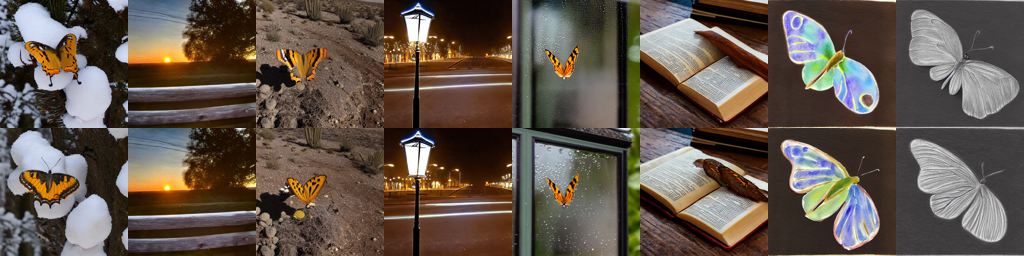

In [16]:
# Задание 11 (бонус), часть 2. Генерации абляции и парное сравнение с основной моделью
if RUN_BONUS:
    main_tag = f'{BONUS_BASE}_step{MAX_STEPS:04d}'
    bonus_tag = f"{bonus_cfg['name']}_step{MAX_STEPS:04d}"
    bonus_dir = checkpoint_dir(bonus_cfg['name'], MAX_STEPS)

    pipe.load_lora_weights(bonus_dir, adapter_name=bonus_tag)
    pipe.set_adapters([bonus_tag])
    generations[bonus_tag], seconds = generate_set(pipe, bonus_tag)
    pipe.delete_adapters(bonus_tag)
    assert lora_param_count(pipe.unet) == 0, 'LoRA абляции не снята'
    image_emb[bonus_tag] = embed_images([ARTIFACTS / r['file'] for r in generations[bonus_tag]])

    def pair_metrics(tag):
        rows, emb = generations[tag], image_emb[tag]
        text = (emb * eval_text_emb[[prompt_index[r['prompt']] for r in rows]]).sum(dim=1).numpy()
        _, nn_cos, _ = nearest_train(emb)
        return rows, text, nn_cos.numpy()

    main_rows, main_text, main_nn = pair_metrics(main_tag)
    abl_rows, abl_text, abl_nn = pair_metrics(bonus_tag)
    assert [(r['prompt'], r['seed']) for r in main_rows] == [(r['prompt'], r['seed']) for r in abl_rows]

    def side(tag, text, nn):
        return {'model': tag, 'clip_text': round(float(text.mean()), 4), 'nearest_train_cos': round(float(nn.mean()), 4),
                'nearest_train_cos_max': round(float(nn.max()), 4), 'n_copy_candidates': int((nn > COPY_THRESHOLD).sum()),
                'diversity': round(diversity(tag), 4)}

    delta = {
        'clip_text': {'mean': round(float((abl_text - main_text).mean()), 4), 'ci95': bootstrap_ci(abl_text - main_text)},
        'nearest_train_cos': {'mean': round(float((abl_nn - main_nn).mean()), 4), 'ci95': bootstrap_ci(abl_nn - main_nn)},
        'diversity': {'mean': round(diversity(bonus_tag) - diversity(main_tag), 4), 'ci95': None},
    }
    expected_sign = {'clip_text': -1, 'nearest_train_cos': +1, 'diversity': -1}

    def verdict(metric):
        d = delta[metric]
        if d['ci95'] is None:
            return 'подтверждено по знаку' if np.sign(d['mean']) == expected_sign[metric] else 'не подтверждено'
        low, high = d['ci95']
        if low <= 0 <= high:
            return 'не подтверждено: CI содержит 0'
        return 'подтверждено' if np.sign(d['mean']) == expected_sign[metric] else 'опровергнуто: значимо в обратную сторону'

    verdicts = {m: verdict(m) for m in delta}
    # Неудачные примеры абляции: сильнее всего потеряли соответствие запросу относительно основной модели
    worst = np.argsort(abl_text - main_text)[:5]
    worst_examples = [{'prompt': abl_rows[k]['prompt'], 'seed': abl_rows[k]['seed'],
                       'ablation_file': abl_rows[k]['file'], 'main_file': main_rows[k]['file'],
                       'clip_text_main': round(float(main_text[k]), 4), 'clip_text_ablation': round(float(abl_text[k]), 4)}
                      for k in worst]

    bonus_results = {'hypothesis': BONUS_HYPOTHESIS,
                     'train': {'main_loss_last_50': training_results[BONUS_BASE]['loss_last_50'],
                               'ablation_loss_last_50': bonus_train['loss_last_50']},
                     'main': side(main_tag, main_text, main_nn), 'ablation': side(bonus_tag, abl_text, abl_nn),
                     'delta_ablation_minus_main': delta, 'verdicts': verdicts,
                     'n_pairs': len(main_rows), 'worst_ablation_examples': worst_examples,
                     'sec_per_image': round(float(np.mean(seconds)), 2) if seconds else None}
    save_json('bonus_results.json', bonus_results)

    # Сетка: верхняя строка — основная модель, нижняя — абляция (seed EVAL_SEEDS[0])
    thumb = 128
    pair_grid = Image.new('RGB', (thumb * len(EVAL_PROMPTS), thumb * 2), 'white')
    for row_i, rows in enumerate((main_rows, abl_rows)):
        for r in rows:
            if r['seed'] == EVAL_SEEDS[0]:
                with Image.open(ARTIFACTS / r['file']) as image:
                    pair_grid.paste(image.convert('RGB').resize((thumb, thumb)),
                                    (int(r['prompt_id'][1:]) * thumb, row_i * thumb))
    pair_grid.save(ARTIFACTS / 'bonus_grid.png')

    m, a = bonus_results['main'], bonus_results['ablation']
    table = '\n'.join(
        f"| {name} | {m[key]} | {a[key]} | {delta[key]['mean']:+.4f} | {delta[key]['ci95'] or '—'} | {verdicts[key]} |"
        for name, key in (('CLIP prompt', 'clip_text'), ('ближайший train', 'nearest_train_cos'),
                          ('разнообразие', 'diversity')))
    (ARTIFACTS / 'bonus.md').write_text(f"""# Бонус: влияние содержания подписей на LoRA

**Гипотеза (зафиксирована {BONUS_HYPOTHESIS['fixed_at']}, до обучения абляции).** {BONUS_HYPOTHESIS['hypothesis']}

**Фактор.** Основная модель: {BONUS_HYPOTHESIS['main']}. Абляция: {BONUS_HYPOTHESIS['ablation']}.

**Неизменно.** {'; '.join(BONUS_HYPOTHESIS['fixed'])}.

**Правило решения.** {BONUS_HYPOTHESIS['decision_rule']}.

| Показатель | {main_tag} | {bonus_tag} | Δ (абл. − осн.) | 95% CI | Вывод |
|---|---|---|---|---|---|
{table}

Кандидатов в копии (cos > {COPY_THRESHOLD}): основная {m['n_copy_candidates']}, абляция {a['n_copy_candidates']}.
Train loss (последние 50 шагов): основная {bonus_results['train']['main_loss_last_50']}, абляция {bonus_results['train']['ablation_loss_last_50']}.

**Интерпретация.** _Заполнить после просмотра `bonus_grid.png` и примеров из `bonus_results.json` → `worst_ablation_examples`._
""", encoding='utf-8')

    print(f"{'показатель':18s} {'основная':>9s} {'абляция':>9s} {'Δ':>8s}  CI95              вывод")
    for name, key in (('CLIP prompt', 'clip_text'), ('ближайший train', 'nearest_train_cos'), ('разнообразие', 'diversity')):
        print(f"{name:18s} {m[key]:>9.4f} {a[key]:>9.4f} {delta[key]['mean']:>+8.4f}  "
              f"{str(delta[key]['ci95'] or '—'):17s} {verdicts[key]}")
    print(f"копии: {m['n_copy_candidates']} → {a['n_copy_candidates']};  "
          f"train loss(50): {bonus_results['train']['main_loss_last_50']} → {bonus_results['train']['ablation_loss_last_50']}")
    display(pair_grid)  # сверху основная модель, снизу абляция; столбцы p00…p07

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

In [ ]:
# Анализ результатов: сводная таблица метрик и времени, неудачные примеры
blind_key = {k['item_id']: k for k in json.loads(KEY_PATH.read_text(encoding='utf-8'))['items']}
human_rows = []
for path in sorted(RATINGS_DIR.glob('ratings_*.csv')):
    with open(path, encoding='utf-8-sig') as f:
        human_rows += [{**r, **blind_key[r['item_id']]} for r in csv.DictReader(f) if r['prompt_match_1to5'].strip()]
human_unique = [r for r in human_rows if 'repeat_of' not in r]  # повторы — только для test-retest

def gen_seconds_per_image(tag):
    """Время генерации по отметкам файлов (кэшированный запуск не пишет таймер)."""
    times = sorted(p.stat().st_mtime for p in (GEN_DIR / tag).glob('*.png'))
    return round((times[-1] - times[0]) / (len(times) - 1), 2) if len(times) > 1 else None

# 1) Сводная таблица: CLIP-метрики (32 пары), слепая оценка (16 уникальных картинок), время
final_rows = []
for s in summary:
    hr = [r for r in human_unique if r['model'] == s['model']]
    cfg_train = training_results.get(s['config']) if s['config'] else None
    final_rows.append({
        'model': s['model'], 'rank': s['rank'], 'lr': s['lr'], 'step': s['step'],
        'clip_text': s['clip_text_mean'], 'd_clip_text': s['clip_text_delta_vs_baseline'],
        'd_clip_text_ci95': s['clip_text_delta_ci95'], 'diversity': s['diversity'],
        'nn_train': s['nearest_train_cos_mean'], 'd_nn_train_ci95': s['nearest_train_delta_ci95'],
        'copy_candidates': s['n_copy_candidates'],
        'human_prompt_match': round(float(np.mean([int(r['prompt_match_1to5']) for r in hr])), 2) if hr else None,
        'human_quality': round(float(np.mean([int(r['quality_1to5']) for r in hr])), 2) if hr else None,
        'human_copied': sum(r['looks_copied_yes_no'] == 'yes' for r in hr), 'human_n': len(hr),
        'train_loss_last_50': s['train_loss_last_50'],
        'train_min': round(cfg_train['sec_per_step'] * s['step'] / 60, 1) if cfg_train else 0.0,
        'gen_sec_per_image': gen_seconds_per_image(s['model']),
    })
with open(ARTIFACTS / 'final_table.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(final_rows[0]))
    writer.writeheader(); writer.writerows(final_rows)

print(f"{'model':21s} {'clipT':>6s} {'ΔclipT':>7s} {'div':>6s} {'nnTr':>6s} {'copy':>4s} "
      f"{'чел.запр':>8s} {'чел.кач':>7s} {'loss50':>7s} {'обуч,мин':>8s} {'с/изобр':>7s}")
for r in final_rows:
    print(f"{r['model']:21s} {r['clip_text']:>6.3f} {r['d_clip_text']:>+7.3f} {r['diversity']:>6.3f} "
          f"{r['nn_train']:>6.3f} {r['copy_candidates']:>4d} {r['human_prompt_match']:>8.2f} {r['human_quality']:>7.2f} "
          f"{(r['train_loss_last_50'] or 0):>7.4f} {r['train_min']:>8.1f} {(r['gen_sec_per_image'] or 0):>7.2f}")

# 2) Где модели ошибаются: по prompts (все модели вместе)
print(f"\n{'prompt':8s} {'чел.запр':>8s} {'чел.кач':>7s} {'CLIP':>6s}  текст")
per_prompt = []
for i, prompt in enumerate(EVAL_PROMPTS):
    pid = f'p{i:02d}'
    hr = [r for r in human_unique if r['prompt_id'] == pid]
    clip_vals = [r['clip_text'] for r in per_image if r['prompt_id'] == pid]
    per_prompt.append({'prompt_id': pid, 'prompt': prompt,
                       'human_prompt_match': round(float(np.mean([int(r['prompt_match_1to5']) for r in hr])), 2),
                       'human_quality': round(float(np.mean([int(r['quality_1to5']) for r in hr])), 2),
                       'clip_text': round(float(np.mean(clip_vals)), 3)})
    p = per_prompt[-1]
    print(f"{pid:8s} {p['human_prompt_match']:>8.2f} {p['human_quality']:>7.2f} {p['clip_text']:>6.3f}  {prompt}")

# 3) Неудачные примеры: по одному на тип ошибки, отбор по фактическим оценкам и метрикам
metric_of = {(r['model'], r['prompt_id'], r['seed']): r for r in per_image}
def human_score(r):
    return int(r['prompt_match_1to5']) + int(r['quality_1to5'])
def worst_for(prompt_id):
    return min((r for r in human_unique if r['prompt_id'] == prompt_id), key=lambda r: (human_score(r), r['model'] == 'baseline', r['model']))  # при равенстве — пример LoRA

failures = []
for pid, kind in (('p03', 'объект пропал: сцена «съела» бабочку (фонарь)'),
                  ('p05', 'объект пропал или бесформенный (книга)'),
                  ('p02', 'пространственное отношение: «sitting on» → рядом с кактусом'),
                  ('p01', 'объект пропал: закат и забор есть, бабочки нет'),
                  ('p07', 'анатомия: несимметричные или лишние крылья (набросок)')):
    r = worst_for(pid)
    failures.append({'kind': kind, 'model': r['model'], 'prompt_id': pid, 'seed': r['seed'], 'file': r['source_file'],
                     'human_prompt_match': int(r['prompt_match_1to5']), 'human_quality': int(r['quality_1to5']),
                     'clip_text': metric_of[(r['model'], pid, r['seed'])]['clip_text']})
# Ошибка метрики: максимальный CLIP среди картинок, которые человек оценил «не соответствует» (1)
bad_for_human = [r for r in human_unique if r['prompt_match_1to5'] == '1']
r = max(bad_for_human, key=lambda r: metric_of[(r['model'], r['prompt_id'], r['seed'])]['clip_text'])
failures.append({'kind': 'ошибка метрики: высокий CLIP при оценке человека 1', 'model': r['model'],
                 'prompt_id': r['prompt_id'], 'seed': r['seed'], 'file': r['source_file'],
                 'human_prompt_match': 1, 'human_quality': int(r['quality_1to5']),
                 'clip_text': metric_of[(r['model'], r['prompt_id'], r['seed'])]['clip_text']})
# Кандидаты в копии по CLIP и вердикт человека по той же картинке
for c in [r for r in per_image if r['copy_candidate']]:
    verdicts_h = [h['looks_copied_yes_no'] for h in human_rows
                  if (h['model'], h['prompt_id'], h['seed']) == (c['model'], c['prompt_id'], c['seed'])]
    failures.append({'kind': f"CLIP-кандидат в копию ({c['nearest_train']}, cos={c['nearest_train_cos']})",
                     'model': c['model'], 'prompt_id': c['prompt_id'], 'seed': c['seed'], 'file': c['file'],
                     'human_copied': verdicts_h or 'не оценивалось', 'clip_text': c['clip_text']})

# Корреляция CLIP и человека по картинкам: насколько автоматическая метрика заменяет ручную
pairs = np.array([(metric_of[(r['model'], r['prompt_id'], r['seed'])]['clip_text'], int(r['prompt_match_1to5']))
                  for r in human_unique])
clip_human_corr = round(float(np.corrcoef(pairs[:, 0], pairs[:, 1])[0, 1]), 3)

analysis = {'final_table': final_rows, 'per_prompt': per_prompt, 'failures': failures,
            'clip_vs_human_prompt_match_pearson': clip_human_corr, 'n_human_unique': len(human_unique),
            'raters': sorted({r['rater_id'] for r in human_rows}),
            'repeat_consistency': analyze_blind_ratings()['repeat_consistency']}
save_json('analysis.json', analysis)

print(f"\nКорреляция CLIP prompt ↔ оценка человека (по {len(human_unique)} картинкам): r = {clip_human_corr}")
print('\nНеудачные примеры:')
for k, f_ in enumerate(failures, 1):
    print(f"{k}. [{f_['kind']}] {f_['model']} {f_['prompt_id']} seed={f_['seed']} CLIP={f_['clip_text']} "
          f"чел.: {f_.get('human_prompt_match', '')}/{f_.get('human_quality', '')} {f_.get('human_copied', '')}")

thumb = 200
fail_grid = Image.new('RGB', (thumb * len(failures), thumb), 'white')
for k, f_ in enumerate(failures):
    with Image.open(ARTIFACTS / f_['file']) as image:
        fail_grid.paste(image.convert('RGB').resize((thumb, thumb)), (k * thumb, 0))
fail_grid.save(ARTIFACTS / 'failures_grid.png')
display(fail_grid)  # слева направо — примеры 1…N в порядке списка выше

### Выводы по измерениям

Все модели сравниваются при одинаковых условиях:
- 28 фото и одни и те же батчи, шум и `t` на каждом шаге;
- seed 42, 400 updates, батч 2, 512 px;
- 8 отложенных prompts × 4 seeds, 30 шагов, guidance 7.5.

CLIP-метрики посчитаны по 32 парам «модель − baseline». Ручная оценка — по 16 уникальным картинкам на модель (seeds 1000–1001), один эксперт. Числа ниже взяты из таблицы выше (`final_table.csv`, `analysis.json`).

**Время.** Обучение: 0.73 с/шаг, примерно 4.9 мин на адаптер (400 шагов) на RTX 3060. Пик видеопамяти в первом запуске задания 6 — 2.8–2.9 ГиБ. Генерация: 4.07 с на изображение у baseline и 4.23–4.26 с с LoRA (+4%, вычисления адаптера). Время генерации определено по отметкам времени файлов.

**1. Все адаптеры немного улучшили соответствие prompt по CLIP.**
- Разница с baseline: от +0.003 до +0.012.
- У 5 из 6 checkpoints 95% CI не содержит 0. Исключение — `r4_lr1e-4_step0400`, CI [−0.003, +0.009].
- Ручная оценка это не подтверждает. Средние по 16 картинкам отличаются от baseline (запрос 3.69, качество 2.69) не больше чем на 0.19 балла, например 3.88 у `r16_lr3e-4_step0200` по запросу. Парная разница с baseline на тех же prompt/seed нигде не превышает двух своих стандартных ошибок (±0.12…0.28). По качеству все разницы положительные (+0.12…+0.19) — слабая тенденция в пользу LoRA, которую 16 картинок и один эксперт не подтверждают. Для сравнения: при повторном показе той же картинки оценка качества у эксперта расходится в среднем на 0.62 балла.

**2. LR сильнее влияет на результат, чем rank.**
- `r16_lr3e-4` сильнее всех меняет изображения: средняя разница пикселей с baseline 29 против 20–23.
- У него наибольший прирост CLIP: +0.012 на шаге 200.
- Это единственная конфигурация, у которой генерации значимо приблизились к train: Δ сходства с ближайшим train +0.018, CI [+0.003, +0.036].

**3. Rank 4 и rank 16 при LR 1e-4 по CLIP не различаются.**
- CLIP prompt: 0.329 и 0.329 на шаге 200.
- У rank 4 ниже разнообразие: 0.124–0.125 против 0.130–0.135.
- Сравнение не чистое: в peft инициализация `gaussian` задаёт A со стандартным отклонением 1/r, поэтому у rank 4 поправка ΔW крупнее (‖ΔW‖ = 7.0 против 3.6).

**4. Шаг 400 не лучше шага 200.**
- У `r4_lr1e-4` прирост CLIP упал с +0.007 до +0.003 и перестал быть значимым.
- У `r16_lr3e-4` сближение с train вернулось к уровню baseline.
- На 28 изображениях эффект набирается к шагу 200.

**5. Признаков запоминания train нет.**
- Только 2 изображения из 192 выше порога копии 0.9022. Это одна и та же пара prompt/seed (p01, seed 1001), ближайшее фото `commons_16.jpg`, cos 0.915 и 0.903, то есть едва выше порога.
- Эксперт оценил обе картинки как «не копия».
- Все модели теряют немного разнообразия: 0.124–0.135 против 0.144 у baseline. Коллапса нет: ближайшими оказываются 6–8 разных train-фото, у baseline 8.

**6. Основные ошибки — от базовой SD 1.5, LoRA их не исправляет.**
- Prompt p03 (фонарь) получил 1.00 / 1.00 у всех 7 моделей, включая baseline: бабочки нет нигде.
- Prompts p01 (забор, 2.86) и p05 (книга, 3.07) — тоже сцены с крупным вторым объектом.
- Стилевые prompts — лучшие по запросу: акварель 4.86, набросок 4.93.

**7. Train loss не различает конфигурации.**
- Loss за последние 50 шагов: 0.1619–0.1627 у всех трёх конфигураций.
- Разброс от шага к шагу (0.13) задаётся уровнем шума `t`, а не адаптером.

**8. CLIP только частично заменяет человека.**
- Корреляция CLIP prompt с оценкой эксперта по 112 картинкам: r = 0.59.
- CLIP поставил 0.34 картинке с фонарём без бабочки — выше среднего по всем генерациям (0.33).
- Акварели, которые эксперт оценил высоко (4.86), CLIP оценил ниже всех (0.299).
- Поэтому абсолютные значения CLIP сравнимы только внутри одного prompt.

**9. Бонус: одинаковые подписи ничего не изменили.**
- Все три разницы с основной моделью в пределах шума, 95% CI содержат 0.
- Подписи из названий файлов Commons описывают автора и место, а не фон кадра.

### Неудачные примеры

Изображения выведены выше слева направо, номер = позиция.

| № | Модель, prompt, seed | Что видно | Почему |
|---|---|---|---|
| 1 | `r16_lr1e-4_step0200`, p03, 1001 | фонарь, бабочки нет; человек 1/1 | SD 1.5 рисует крупный второй объект и теряет мелкий главный; при guidance 7.5 сильный «фонарный» контекст в обучении SD перевешивает |
| 2 | `r16_lr1e-4_step0200`, p05, 1000 | раскрытая книга, бабочки нет; 1/1 | та же причина; в 28 train-фото бабочка всегда крупная и на растении, сцен с предметами нет |
| 3 | `r16_lr1e-4_step0200`, p02, 1000 | бабочка на земле, кактусы рядом; 3/3 | SD 1.5 слабо передаёт пространственные отношения: «sitting on» превращается в «рядом с» |
| 4 | `r16_lr1e-4_step0200`, p01, 1000 | закат и забор, бабочки нет; 1/1 | сцена «закат» занимает весь кадр; бабочка на фоне неба — редкий для SD случай |
| 5 | `r16_lr1e-4_step0200`, p07, 1000 | набросок, справа одно крыло вместо двух; 4/3 | U-Net не следит за числом и симметрией частей; рисунок ракурса 3/4 сложнее фото в профиль |
| 6 | `r16_lr3e-4_step0400`, p03, 1000 | фонарь, бабочки нет; человек 1, CLIP 0.34 | ошибка метрики: CLIP на 224 px отвечает на «street lamp, city, night» и почти не штрафует пропуск мелкой бабочки |
| 7 | `r16_lr1e-4_step0200`, p01, 1001 | бабочка на заборе; CLIP-кандидат в копию (0.915) | окраска похожа на `commons_16` (Common Jezebel), но поза и сцена другие; человек: «не копия», порог задан самой похожей парой train-фото и пограничен |
| 8 | `r16_lr3e-4_step0200`, p01, 1001 | бабочка висит перед забором, справа нет заднего крыла; кандидат в копию (0.903) | тот же seed тянется к виду `commons_16`; плюс асимметрия крыльев — та же ошибка, что в примере 5 |

Примеры 1 и 6 — один и тот же prompt у разных конфигураций, и композиция почти совпадает. Адаптер меняет текстуру и окраску, но не композицию, которую задают prompt и seed.

### Ограничения

- **Эксперт один, и это автор работы.** Он знал, какие модели обучались, хотя картинки видел под случайными кодами. 16 уникальных картинок на модель мало, чтобы различить разницу в 0.2 балла.
- **Один запуск обучения на конфигурацию.** Разброс между seed обучения не измерен, поэтому разница между конфигурациями может быть частично случайной.
- **Данные:** 28 фото разных видов бабочек и шумные подписи из названий файлов. `sks butterfly` означает «бабочки этого набора», а не один экземпляр.
- **CLIP ViT-B/32 смотрит на 224 px** и плохо замечает пропуск мелкого объекта (пример 6). Абсолютные значения несравнимы между prompts.
- **Порог копии задан по данным (0.9022)** и ловит 93% искажённых копий. Ниже порога копирование не исключено.
- **Сравнение rank 4 и rank 16 смешано с масштабом инициализации A** (std 1/r).
- **Отложенная выборка — это prompts, а не изображения.** Отложенных фото бабочек нет.
- **CC0 подтверждён по метаданным Commons,** а не юридической экспертизой.

### Проверяемые выводы

1. При повторном запуске с теми же seeds `generation_metrics.jsonl` воспроизводится. Контроль: повторная генерация baseline дала mean |Δpix| = 0.000.
2. Для `r16_lr3e-4_step0200` 95% CI разницы CLIP prompt с baseline лежит выше 0: [+0.004, +0.021].
3. Ни одна модель не даёт картинок выше порога копии, кроме пары p01/seed 1001.
4. Prompt p03 не решается ни одной моделью: средняя ручная оценка соответствия 1.00.
5. Парная разница ручных оценок любой LoRA-модели с baseline не превышает двух стандартных ошибок.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

In [ ]:
# Требования к сдаче: конфигурация, версии, источники/лицензии, checkpoints, контрольные суммы артефактов
import platform
from datetime import datetime, timezone

REQUIRED_ARTIFACTS = ['data_validation.json', 'eval_prompts.json', 'baseline_info.json', 'dataset_summary.json',
                      'lora_configs.json', 'training_summary.json', 'clip_info.json', 'nearest_train_reference.json',
                      'eval_checkpoints.json', 'model_metrics.json', 'generation_metrics.jsonl', 'blind_summary.json',
                      'blind_key.json', 'final_table.csv', 'analysis.json', 'comparison_grid.png', 'failures_grid.png']
missing = [name for name in REQUIRED_ARTIFACTS if not (ARTIFACTS / name).is_file()]
assert not missing, f'Нет обязательных артефактов: {missing}. Запустите ноутбук целиком.'
assert not FAST_DEV_RUN, 'Для сдачи нужен полный режим (FAST_DEV_RUN = False)'

def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

checkpoints = {}
for m in EVAL_MODELS:
    if m['lora_dir']:
        weights = ARTIFACTS / m['lora_dir'] / 'pytorch_lora_weights.safetensors'
        checkpoints[m['tag']] = {'path': m['lora_dir'], 'bytes': weights.stat().st_size,
                                 'sha256': hashlib.sha256(weights.read_bytes()).hexdigest()}

run_info = {
    'created_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'fast_dev_run': FAST_DEV_RUN, 'seed': SEED,
    'python': platform.python_version(), 'platform': platform.platform(),
    'packages': {p: package_version(p) for p in ['torch', 'torchvision', 'diffusers', 'transformers', 'accelerate',
                                                 'peft', 'safetensors', 'pillow', 'numpy', 'matplotlib', 'ipywidgets']},
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'resources': {
        'notebook_wall_minutes': round((time.time() - NOTEBOOK_T0) / 60, 1),
        'train_sec_per_step': {name: r['sec_per_step'] for name, r in training_results.items()},
        'generation_sec_per_image': {r['model']: r['gen_sec_per_image'] for r in final_rows},
    },
    'sources': {
        'data': {'source': 'Wikimedia Commons, 28 фото бабочек', 'license': 'CC0-1.0 (проверено по extmetadata каждого файла)',
                 'script': 'download_open_data.py', 'metadata': str(DATA_ROOT / 'metadata.jsonl')},
        'generator': {'model': MODEL_ID, 'license': 'CreativeML OpenRAIL-M'},
        'evaluator': {'model': CLIP_ID, 'license': 'MIT (OpenAI CLIP)'},
    },
    'config': {'resolution': RESOLUTION, 'max_steps': MAX_STEPS, 'checkpoint_steps': CHECKPOINT_STEPS,
               'batch_size': TRAIN_BATCH_SIZE, 'schedule': TRAIN_SCHEDULE, 'lora_targets': LORA_TARGETS,
               'lora_configs': LORA_CONFIGS, 'inference': INFERENCE, 'eval_prompts': EVAL_PROMPTS,
               'eval_seeds': EVAL_SEEDS, 'eval_spec_sha256': EVAL_SPEC_SHA256, 'copy_threshold': COPY_THRESHOLD},
    'checkpoints': checkpoints,
    'artifacts': {f.name: {'bytes': f.stat().st_size, 'sha256': hashlib.sha256(f.read_bytes()).hexdigest()}
                  for f in sorted(ARTIFACTS.iterdir()) if f.is_file() and f.name != 'run_info.json'},
}
save_json('run_info.json', run_info)
print(json.dumps({k: run_info[k] for k in ('packages', 'gpu', 'resources', 'sources')}, ensure_ascii=False, indent=2))
print(f"Артефактов: {len(run_info['artifacts'])}, checkpoints: {len(checkpoints)}; обязательные на месте.")

### Инструкция повторного запуска

1. **Окружение.**
   - Python 3.12 и GPU с CUDA (проверено на NVIDIA RTX 3060, 12 ГБ). Точные версии пакетов записаны в `artifacts/lab13/run_info.json`.
   - Установка: `pip install torch torchvision diffusers transformers accelerate peft safetensors pillow numpy matplotlib ipywidgets`.
2. **Входы.**
   - В корне проекта должен лежать `download_open_data.py`. При первом запуске задание 1 скачает 28 фото с Wikimedia Commons, нужен интернет.
   - SD 1.5 (`stable-diffusion-v1-5/stable-diffusion-v1-5`, ~4 ГБ) и CLIP (`openai/clip-vit-base-patch32`) скачиваются с Hugging Face.
   - Фото и веса не коммитить в Git.
3. **Запуск.**
   - Сначала `FAST_DEV_RUN = True`: 256 px, 1 шаг — проверка связности.
   - Затем `FAST_DEV_RUN = False` и **Restart & Run All**: ячейки зависят друг от друга.
   - Без GPU полный режим остановится в задании 3 с явной ошибкой.
4. **Пути и переменные окружения.**
   - Артефакты пишутся в `artifacts/lab13/`, данные — в `data/lab13/`.
   - Переопределяются через `CV_ARTIFACTS` и `CV_LORA_DATA`; модели — через `CV_SD_MODEL` и `CV_CLIP_MODEL`.
5. **Кэш и возобновление.**
   - Готовые генерации (`generations/*/*.png`) не перегенерируются.
   - Обучение продолжается с последнего полного checkpoint (`checkpoints/<конфигурация>/step_XXXX/COMPLETE`), а полностью обученные конфигурации пропускаются.
   - Для длительного обучения в Colab укажите `CV_ARTIFACTS` на папку Google Drive.
   - Для полного пересчёта удалите `artifacts/lab13/` (кроме `blind_ratings/`, если оценки нужно сохранить).
6. **Ручная оценка.**
   - Ячейка после задания 10 открывает форму. Оценки сохраняются в `blind_ratings/ratings_<эксперт>.csv` и переживают перезапуск.
   - Ключ `blind_key.json` экспертам не передавать.
7. **Проверка воспроизводимости.**
   - `eval_spec_sha256` = `de044a645f01a2ee49ba85e71a1322fed2fadebaf0217b37e9bd88931d85976a`.
   - Повторная генерация baseline с тем же seed даёт mean |Δpix| = 0.000.
   - `run_info.json` содержит sha256 всех артефактов и весов LoRA.
8. **Что сдавать.**
   - Папку `artifacts/lab13/`: checkpoints, generations, `final_table.csv`, `analysis.json`, `comparison_grid.png`, `failures_grid.png`, `blind_ratings/`, `bonus.md`, `run_info.json`.
   - Сам ноутбук с выводами ячеек.